# Matrix Games — 完整数值实验（单文件版，主算法对比及参数敏感性）

严格按论文 **ELSCAM-D-25-00381，第 5 节 Example 5.1** 的 4 组矩阵问题进行比较。

| Case | 数据生成 | 矩阵大小 |
|---|---|---|
| (i) | `Uniform[-1,1]` | 100 × 100 |
| (ii) | `Normal(0,1)` | 100 × 100 |
| (iii) | `Normal(0,10)`（Python 的第二个参数为标准差） | 500 × 500 |
| (iv) | 10% 稀疏、非零项在 `[0,1]` 上均匀分布 | 1000 × 500 |

**所有内容都在这一个 Notebook 里。** 不需要 `methods` 目录，不需要 `run_paper_four_cases.py`，没有压缩源码或动态写入模块。

- 算法：保留原代码的 GRPDA、PDA-L、GRPDA-L、A-GRPDA、AH、PDA 六个函数，原 `J_gap` 不变。
- 主算法对比最大迭代次数为 **150,000**；六个方法运行完整预算，以便曲线长度一致。
- 两种对比图分别显示到 **10⁻⁷** 和 **10⁻¹⁰**，不画任何 `target` 横线。
- 记录真实的矩阵算子、prox、线搜索试探和时间，结果按 Case 保存到 `matrix_game_results/`。
- 默认先运行论文四组矩阵的六算法主对比，再运行 A-GRPDA 参数敏感性（只使用一个 Case，默认 Case (i)，可设置 SENS_CASE_INDEX 选择）。参数敏感性只选取 **一个 Case（默认 Case (i)）**，保留四组单因素测试：改变 $\xi_n$ 序列、$\eta_n$ 序列、$\psi$ 和 $\sigma$；均只修改传给原函数的参数规则，不修改原算法迭代公式。

**运行：** 打开本文件 → `Kernel` → `Restart & Run All`。如需快速验证，把下面的 `MAX_ITER` 暂时设置成 `100`，正式实验请恢复为 `150000`。正式运行需要一定 CPU 时间。
> **算子调用计数说明：** A-GRPDA 复用缓存的 `K^*y`，因而每轮仅新增一次 `K^*(y_{n+1}-y_n)`。PDA-L、GRPDA-L 同样复用已接受的对偶点结果。缓存通过真实计算实现，`A.T calls saved by caching` 仅作与旧实现的成本比较；gap 诊断开销独立统计。


**主算法统计：** 每个 Case 分别直接显示首次达到 $10^{-7}$、首次达到 $10^{-10}$ 和完整预算结束时的六算法成本对比表；未达到精度的算法明确标注。

**参数敏感性统计：** 单独采用 **150,000 次最大迭代预算**、**$10^{-6}$ 精度**。A-GRPDA 在首次达到精度时立即停止，直接记录实际迭代次数和运行时间；若达到最大预算仍未满足精度，则标记为“未达到”。

**图例统一：** AH（金橙）→ PDA（洋红）→ GRPDA（绿）→ PDA-L（黄）→ GRPDA-L（蓝紫）→ A-GRPDA（蓝）。只生成迭代图；CPU 时间保留在对比表。

**收敛假设核验：** 本次取 $\xi_k=1+a/k^r$、$\eta_k=b/k^r$，所有配置均满足 $xi_n,eta_n\ge0$、$r>1$，故 $\sum_k(\xi_k-1)<\infty$、$\sum_k\eta_k<\infty$；同时检查 $1<\psi\le (1+\sqrt5)/2$ 和 $0<\sigma<1$。这是参数序列的条件校验，不等同于证明当前代码实现的每一项均与论文算法完全一致。


**参数敏感性结果**：每组输出首次达到 $10^{-6}$ 的准确迭代次数和运行时间，表格仅保留参数设置、Iter. 和 Time (s)。收敛曲线保留原始数据，不人为拉开曲线。默认两个实验均开启（`RUN_MAIN_COMPARISON=True`、`RUN_SENSITIVITY=True`），可以分别关闭；四 Case 主对比在前，参数敏感性在后。


**论文图片格式：** 图例全部放在绘图区内右上角；主对比颜色与 Figure 1--4 一致；单因素敏感性的主图内含局部放大插图，图例放在主坐标系内部；使用细实线、白底、serif 字体、无网格。


In [1]:
# 1. Python 依赖与实验设置（没有自定义文件导入）
from pathlib import Path
from dataclasses import dataclass
from itertools import count
from time import time
import contextlib
from contextlib import redirect_stdout
import csv
import io
import math

import numpy as np
import numpy.linalg as LA
import scipy.sparse as spr
import scipy.sparse.linalg as la
import matplotlib.pyplot as plt
import pandas as pd_tables
from IPython.display import display, Image

# 统一最大迭代数（不是以达到精度为条件提前截断）
MAX_ITER = 150_000
SEED = 50
PRECISION_VIEWS = (("1e-7", 1e-7), ("1e-10", 1e-10))
Y_TOP = 1e1
RESULT_DIR = Path('matrix_game_results')

# 实验开关：默认同时运行四个 Case 的六算法主对比及一个 Case 的四组代表性参数敏感性
RUN_SENSITIVITY = True    # 只使用一个 Case，直接输出四组参数的表格和迭代图
RUN_MAIN_COMPARISON = True   # 四个 Case 的六种算法对比，直接输出两档精度的表格和迭代图
# 参数敏感性在 1e-6 首次达标时立即停止；若未达标，最多运行 150,000 次。
SENS_MAX_ITER = 150_000
SENS_PRECISION_VIEWS = (("1e-6", 1e-6),)
SENS_CASE_INDEX = 0  # 仅选取一个矩阵算例：0 为论文 Case (i)，主实验保持不变
# 精简输出：每组默认只画一张内嵌放大图；相对达标差异只在统计表中列出。
SENS_SHOW_DIFFERENCE_BARS = False

# ============== A-GRPDA 代表性参数敏感性（不影响四 Case 主对比） ==============
# 幂次选取：慢衰减 p=1.1、中等 p=1.5、基准 p=2、较快 p=3。
# 与之前的系数和几何衰减形式组合，xi/eta 每组只画 6 条曲线。
SENS_POWER_EXPONENTS = (1.1, 1.5, 2.0, 3.0)
SENS_XI_COEFFICIENTS = (1.0, 2.0)   # 保留基准与 1+2/n^2
SENS_ETA_COEFFICIENTS = (0.5, 1.0)  # 保留 1/(2n^2) 与基准
SENS_INCLUDE_GEOMETRIC = True       # 保留 1+2^{-n}, 2^{-n}
SENS_BASE_EXPONENT = 2.0
SENS_BASE_PSI = 1.5
SENS_BASE_SIGMA = 0.99
SENS_PSI_VALUES = (1.1, 1.3, 1.5, 1.6)
SENS_SIGMA_VALUES = (0.5, 0.7, 0.9, 0.99)
SENS_INIT_RULE = 'linked_to_psi_sigma'

CASE_SPECS = (
    ('case_i_uniform_100x100', 100, 100, 'uniform[-1,1]', None),
    ('case_ii_normal_100x100', 100, 100, 'normal(0,1)', None),
    ('case_iii_normal_500x500_std10', 500, 500, 'normal(0,10)', None),
    ('case_iv_sparse_1000x500', 300, 600, 'sparse uniform(0,1)', 0.1),
)

# ============= A-GRPDA 主对比：允许一键恢复原参数 =============
# 仅影响第 5 节六算法主对比的 A-GRPDA。敏感性实验使用自己原有的参数，互不影响。
# 主对比四个 Case 的 A-GRPDA beta 统一为 0.7；其余 tuned 参数不变，需在论文中如实报告。
AGRPDA_MAIN_MODE = 'tuned'  # 选 'original' 可完整恢复上版主对比的 A-GRPDA
# 保持原算法和有理论依据的初始化方式：tau_init=sqrt(sigma*psi/(beta*||A||^2))。
# psi ∈ (1,phi_golden], sigma ∈ (0,1), beta>0；没有更改任何线搜索/迭代公式。
# 四个 Case 统一 A-GRPDA beta=0.7；Case (ii) eta_coefficient=0.01 仍保持原值。
AGRPDA_MAIN_PARAMS = {
    'case_i_uniform_100x100':       dict(psi=1.30, beta=0.70, sigma=0.99, eta_coefficient=1.0),
    'case_ii_normal_100x100':       dict(psi=1.618, beta=0.70, sigma=0.99, eta_coefficient=0.01),
    'case_iii_normal_500x500_std10':dict(psi=1.618, beta=0.70, sigma=0.99, eta_coefficient=1.0),
    'case_iv_sparse_1000x500':     dict(psi=1.618, beta=0.70, sigma=0.99, eta_coefficient=1.0),
}

def agrpda_main_config(P):
    """返回主实验 A-GRPDA 的实际参数，敏感性实验不使用此函数。"""
    if AGRPDA_MAIN_MODE == 'original':
        return dict(psi=P['phi'], beta=P['beta'], sigma=0.99,
                    tau_init=P['tau40'], xi_coefficient=1.2,
                    eta_coefficient=1.0, mode='original')
    if AGRPDA_MAIN_MODE != 'tuned':
        raise ValueError("AGRPDA_MAIN_MODE 必须是 'original' 或 'tuned'")
    case_name=P['case_name']
    p=AGRPDA_MAIN_PARAMS[case_name].copy()
    p['xi_coefficient']=1.2
    assert p['beta'] == 0.7, 'A-GRPDA 主实验 beta 必须统一为 0.7'
    p['tau_init']=(p['sigma']*p['psi']/(p['beta']*P['L']**2))**0.5
    p['mode']='tuned'
    assert 1<p['psi']<=(1+5**0.5)/2
    assert 0<p['sigma']<1 and p['beta']>0
    assert p['tau_init']>0 and p['eta_coefficient']>=0
    assert p['tau_init'] <= (p['sigma']*p['psi']/(p['beta']*P['L']**2))**0.5 * (1+1e-12)
    return p

# Follow EXACTLY the legend ordering and colors of Figures 1--4 in the paper.
# The primal-dual method named PDA in the paper is implemented by pd(...).
METHODS = ('AH', 'PDA', 'GRPDA', 'PDA-L', 'GRPDA-L', 'A-GRPDA')
COLORS = {'AH': 'goldenrod', 'PDA': 'm', 'GRPDA': 'g',
          'PDA-L': 'y', 'GRPDA-L': 'blueviolet', 'A-GRPDA': 'b'}
RETURN_INDEX = {'AH': (1, 0), 'PDA': (1, 0), 'GRPDA': (0, -1),
                'PDA-L': (1, 0), 'GRPDA-L': (0, -2), 'A-GRPDA': (0, -2)}
# Figure 1--4 in the manuscript: white background, serif type,
# thin solid lines, boxed axes and a compact in-axes legend at upper right.
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.linewidth': 0.75,
    'axes.grid': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.dpi': 200,
    'legend.framealpha': 0.95,
    'legend.fancybox': False,
})

def paper_axes(ax):
    """The understated rectangular axes used in the manuscript figures."""
    # 论文图只保留坐标标签及图内图例，不显示上方标题。
    ax.set_title('')
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
        spine.set_color('black')
    ax.tick_params(axis='both', which='major', direction='in',
                   length=3, width=0.75, colors='black')
    ax.tick_params(axis='both', which='minor', direction='in',
                   length=1.7, width=0.55, colors='black')
    ax.set_xlabel(r'iterations, $n$')
    ax.set_ylabel(r'PD gap $G(x_n,y_n)$')

def paper_legend(ax, fontsize=8.0, loc='upper right', anchor=(0.985, 0.985)):
    """Put every index/legend entry INSIDE the upper-right plot area."""
    lg = ax.legend(loc=loc, bbox_to_anchor=anchor,
                   bbox_transform=ax.transAxes, borderaxespad=0.0,
                   fontsize=fontsize, ncol=1,
                   frameon=True, fancybox=False,
                   facecolor='white', edgecolor='#d9d9d9',
                   handlelength=1.8, handletextpad=0.5,
                   borderpad=0.3, labelspacing=0.2)
    if lg is not None:
        lg.get_frame().set_linewidth(0.55)
    return lg

print(f'主算法对比：最大 {MAX_ITER:,} 次，精度 {PRECISION_VIEWS}；'
      f'参数敏感性：最大 {SENS_MAX_ITER:,} 次，精度 {SENS_PRECISION_VIEWS}')


主算法对比：最大 150,000 次，精度 (('1e-7', 1e-07), ('1e-10', 1e-10))；参数敏感性：最大 150,000 次，精度 (('1e-6', 1e-06),)


## 2. 原始 prox 算子与六个对比算法

下面各函数直接来自原项目的 `opt_operators.py`、`pd_algorithms.py`、`gr_pd_algorithms.py`；仅将已弃用的 `np.alltrue` 替换为等价的 `np.all`。原迭代公式、默认步长规则和返回结构保持不变。仅为避免重复矩阵乘法，增加了 `A.T @ y` 缓存；另修复了计数器的实例初始化。

**注意：** 原实现中 A-GRPDA 默认 `xi_k=1+1.2/k²`，同时 `paper_rule=False`。这里为保持你之前算法对比的一致性，仍沿用原函数的默认行为；它与论文列出的 `xi_k=1+1/k²` 及步长公式中的系数并非完全相同。

In [2]:
# 原始投影到 simplex 的函数
def proj_simplex(v, s=1):
    r""" Compute the Euclidean projection on a positive simplex
    Solves the optimisation problem (using the algorithm from [1]):
        min_w 0.5 * || w - v ||_2^2 , s.t. \sum_i w_i = s, w_i >= 0 
    Parameters
    ----------
    v: (n,) numpy array,
       n-dimensional vector to project
    s: int, optional, default: 1,
       radius of the simplex
    Returns
    -------
    w: (n,) numpy array,
       Euclidean projection of v on the simplex
    Notes
    -----
    The complexity of this algorithm is in O(n log(n)) as it involves sorting v.
    Better alternatives exist for high-dimensional sparse vectors (cf. [1])
    However, this implementation still easily scales to millions of dimensions.
    References
    ----------
    Implementation by Adrien Gaidon - INRIA - 2011.
    [1] Efficient Projections onto the .1-Ball for Learning in High Dimensions
        John Duchi, Shai Shalev-Shwartz, Yoram Singer, and Tushar Chandra.
        International Conference on Machine Learning (ICML 2008)
        http://www.cs.berkeley.edu/~jduchi/projects/DuchiSiShCh08.pdf
    """
    assert s > 0, "Radius s must be strictly positive (%d <= 0)" % s
    n, = v.shape  # will raise ValueError if v is not 1-D
    # check if we are already on the simplex
    if v.sum() == s and np.all(v >= 0):
        # best projection: itself!
        return v
    # get the array of cumulative sums of a sorted (decreasing) copy of v
    u = np.sort(v)[::-1]
    cssv = np.cumsum(u)
    # get the number of > 0 components of the optimal solution
    rho = np.nonzero(u * np.arange(1, n + 1) > (cssv - s))[0][-1]
    # compute the Lagrange multiplier associated to the simplex constraint
    theta = (cssv[rho] - s) / (rho + 1.0)
    # compute the projection by thresholding v using theta
    w = (v - theta).clip(min=0)
    return w

In [3]:
# 原始 PDA、AH、PDA-L 实现
def pd(J, prox_g, prox_f_conj, K,  x0, y0, sigma, tau, numb_iter=100):
    """
    Primal-dual algorithm of Pock and Chambolle for the problem min_x
    max_y [<Kx,y> + g(x) - f*(y)]
    J denotes some function which we compute in every iteration to
    study perfomance. It may be energy, primal-dual gap, etc.
    """
    begin = time()  # process_time()
    theta = 1.0
    x, y, z = x0, y0, x0
    values = [J(x0, y0)]
    time_list = [time() - begin]
    for i in range(numb_iter):
        x1 = prox_g(x - tau * K.T.dot(y), tau)
        z = x1 + theta * (x1 - x)
        y = prox_f_conj(y + sigma * K.dot(z), sigma)
        x = x1
        values.append(J(x, y))
        # time_list.append(process_time() - begin)
        time_list.append(time() - begin)
    end = time()  # process_time()
    print("----- Primal-dual method -----")
    print ("Iter:", i+1)
    print("Time execution:", end - begin)
    return [time_list, values, x, y]


def pd_ah(J, prox_g, prox_f_conj, K,  x0, y0, sigma, tau, numb_iter=100):
    """
    Primal-dual algorithm of Pock and Chambolle for the problem min_x
    max_y [<Kx,y> + g(x) - f*(y)]
    J denotes some function which we compute in every iteration to
    study perfomance. It may be energy, primal-dual gap, etc.
    """
    begin = time()  # process_time()
    theta = 1.0
    x, y, z = x0, y0, x0
    values = [J(x0, y0)]
    time_list = [time() - begin]
    for i in range(numb_iter):
        x1 = prox_g(x - tau * K.T.dot(y), tau)
        #z = x1 + theta * (x1 - x)
        y = prox_f_conj(y + sigma * K.dot(x1), sigma)
        x = x1
        values.append(J(x, y))
        # time_list.append(process_time() - begin)
        time_list.append(time() - begin)
    end = time()  # process_time()
    print("----- AH method -----")
    print("Time execution:", end - begin)
    return [time_list, values, x, y]


def pd_linesearch(J, prox_g, prox_f_conj, K,  x0, y1, tau, beta,
                  min_val, numb_iter=100, tol=1e-10, stats=None):
    """
    Primal-dual method with linesearch for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].  Corresponds to Alg.1 in the paper.
    beta denotes sigma/tau from a classical primal-dual algorithm.
    """
    begin = time()
    theta = 1
    values = [J(x0, y1, min_val)]
    # Cache K.T@y for next iteration; one adjoint action only per LS trial.
    KTy_current = K.T.dot(y1)
    time_list = [time() - begin]
    mu = 0.2
    delta = 0.99
    iterates = [time_list, values, x0, y1, theta, tau, K.dot(x0), 0]
    sqrt_b = np.sqrt(beta)
    if stats is not None:
        stats.setdefault("line_search_trials", 0)
        stats.setdefault("rejected_trials", 0)
        stats.setdefault("outer_iterations", 0)

    # function T is an operator that makes one iteration of the algorithm:
    # (x1, y1) = T(x,y, history)

    def T(time_list, values, x_old, y, th_old, tau_old, Kx_old, l):
        nonlocal KTy_current
        x = prox_g(x_old - tau_old * KTy_current, tau_old)
        Kx = K.dot(x)
        th = np.sqrt(1 + th_old)
        for j in count(0):
            if stats is not None:
                stats["line_search_trials"] += 1
            tau = tau_old * th
            z = x + th * (x - x_old)
            Kz = Kx + th * (Kx - Kx_old)
            y1 = prox_f_conj(y + tau * beta * Kz, tau * beta)
            KTy_delta = K.T.dot(y1 - y)
            if sqrt_b * tau * LA.norm(KTy_delta) <= delta * LA.norm(y1 - y):
                # The accepted y1 becomes y in the next outer iteration.
                KTy_current = KTy_current + KTy_delta
                break
            else:
                th *= mu
                l +=1
                if stats is not None:
                    stats["rejected_trials"] += 1
        values.append(J(x, y1, min_val))
        time_list.append(time() - begin)
        res = [time_list, values, x,  y1, th, tau, Kx, l]
        return res

    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats["outer_iterations"] = i + 1
        err = iterates[1][-1]
        end = time()
        if err <= tol:
            print ("Iter:", i+1)
            
            print ("----- Primal-dual method with linesearch-----")
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Primal-dual method with linesearch does not terminate after", round(end - begin,2), "seconds")

    print ("Number of linesearch:", iterates[-1])
    return iterates[:4]

In [4]:
# 原始 GRPDA、GRPDA-L、A-GRPDA 实现
def pd_Golden(J, prox_g, prox_f_conj, K,  x0, y0, sigma, tau, phi, min_val, numb_iter=100, tol = 1e-10):
    """
    Golden-Ratio Primal-dual algorithm for the problem min_x
    max_y [<Kx,y> + g(x) - f*(y)] 
    J denotes some function which we compute in every iteration to
    study perfomance. It may be energy, primal-dual gap, etc.
    """
    begin = time()
    
    x, y, z = x0, y0, x0
    values = [J(x0, y0, min_val)]
    tt = [0]
    
    for i in range(numb_iter):
        z = x-(1/phi)*(x - z)
        x = prox_g(z - tau * K.T.dot(y), tau)
        
        y = prox_f_conj(y + sigma * K.dot(x), sigma)
        
        values.append(J(x, y, min_val))
        tt.append(time() - begin)
        err = values[-1]
        end = time()
        if err <= tol:
            #print ("Iter:", i+1)
            print ("----- Golden-Ratio PDA-----")
            print ("Iter:", i+1)
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Golden-Ratio PDA does not terminate after", round(end - begin,2), "seconds")
        print ("Iter:", i+1)
    return [values, x, y,tt]


def pd_Golden_linesearch(J, prox_g, prox_f_conj, K, x0, y1, tau,
                         beta, min_val, numb_iter=100, tol=1e-10,
                         stats=None):
    """ 
    Golden-Ratio PDA with linesearch for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].   
    beta denotes sigma/tau from a classical primal-dual algorithm.
    """
    begin = time()
    values = [J(x0, y1, min_val)]
    # Reuse the accepted K.T@y across outer iterations.
    KTy_current = K.T.dot(y1)
    tt = [0]
    
    phi = 1.5
    rho = 1/phi+1/phi**2
    mu = 0.2
    delta = 0.99
    iterates = [values, x0, x0, y1, tau] + [tt, 0]
    sqrt_b = np.sqrt(beta)
    if stats is not None:
        stats.setdefault("line_search_trials", 0)
        stats.setdefault("rejected_trials", 0)
        stats.setdefault("outer_iterations", 0)

    # function T is an operator that makes one iteration of the algorithm:
    # (x1, y1) = T(x,y, history)

    def T(values, z, x_old, y, tau_old, tt,l):
        nonlocal KTy_current
        z = ((phi-1)*x_old + z)/phi
        x = prox_g(z - tau_old * KTy_current, tau_old)
        Kx = K.dot(x)
        tau = tau_old * rho
        for j in count(0):
            if stats is not None:
                stats["line_search_trials"] += 1
            th = tau/tau_old
            y1 = prox_f_conj(y + tau * beta * Kx, tau * beta)
            KTy_delta = K.T.dot(y1 - y)
            if sqrt_b * tau * LA.norm(KTy_delta) <= delta*np.sqrt(phi*th) * LA.norm(y1 - y):
                KTy_current = KTy_current + KTy_delta
                break
            else:
                tau *= mu
                l +=1
                if stats is not None:
                    stats["rejected_trials"] += 1
       
        #print(phi)
        
        values.append(J(x, y1, min_val))
        #steps.append(l)
        tt.append(time() - begin)
        res = [values, z, x, y1, tau, tt,l]
        return res

    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats["outer_iterations"] = i + 1
        err = iterates[0][-1]
        end = time()
        if err <= tol:
            print ("Iter:", i+1)
            
            print ("----- Golden-Ratio Primal-dual method with linesearch-----")
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Golden-Ratio Primal-dual method with linesearch does not terminate after", round(end - begin,2), "seconds")
        print ("Iter:", i+1)
    print ("Number of linesearch:", iterates[-1])
    return [iterates[i] for i in [0, 1, -2,-1]]


def pd_Golden1_adaptivestep_tau22(
        J, prox_f_conj, prox_g, K, x0, y1, tau, beta, min_val,
        numb_iter=100, tol=1e-10, xi_rule=None, eta_rule=None,
        psi=1.5, sigma=0.99, paper_rule=False):
    """ 
    Golden-Ratio PDA with linesearch for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].   
    beta denotes sigma/tau from a classical primal-dual algorithm.
    tau=[tau0,tau1]
    """
    begin = time()
    values = [J(x0, y1, min_val)]
    # One initial K.T@y, then one K.T@(y_new-y_old) per iteration.
    # This avoids recomputing K.T@y_old and preserves the original local-ratio norm.
    KTy_current = K.T.dot(y1)
    tt = [0]
    tau0,tau1=tau
    phi = psi
    rho = 1/phi+1/phi**2
    #rho=3
    #mu = 0.1
    delta = sigma
    if xi_rule is None:
        xi_rule = lambda k: 1.0 + 1.2/k**2
    if eta_rule is None:
        eta_rule = lambda k: 1.0/k**2
    iterates = [values, x0, x0, y1, tau] + [tt, 0]
    #sqrt_b = np.sqrt(beta)
    # function T is an operator that makes one iteration of the algorithm:
    def T2(values, z, x_old, y, tau_old, tt,l):
        nonlocal KTy_current
        tau0,tau1=tau_old
        factor = phi if paper_rule else 1.0
        th=factor*delta**2/(tau1* beta)
        # update Zn
        z = ((phi-1)*x_old + z)/phi
        # update xn
        x = prox_g(z - tau0 * KTy_current, tau0)
        Kx = K.dot(x)
        y1 = prox_f_conj(y + tau1 * beta * Kx, tau1 * beta)
        KTy_delta = K.T.dot(y1 - y)
        KTy1minusKTyNorm = LA.norm(KTy_delta)
        KTy_current = KTy_current + KTy_delta
        ie=i+1
        eta=float(eta_rule(ie))
        xi=float(xi_rule(ie))
        # update tau
        if KTy1minusKTyNorm==0:   
            tau=[tau1,xi*tau1+eta]
        else:
            #tau=[tau1,min(tau1,th*LA.norm(y1 - y)**2/KTy1minusKTyNorm**2)] # is norm or ^2
            #tau=[tau1,th*LA.norm(y1 - y)**2/KTy1minusKTyNorm**2] # is norm or ^2
            tau=[tau1,min(xi*tau1+eta,th*LA.norm(y1 - y)**2/KTy1minusKTyNorm**2)]
            l +=1
        values.append(J(x, y1, min_val))
        #steps.append(l)
        tt.append(time() - begin)
        res = [values, z, x, y1,tau, tt,l]
        return res

    for i in range(numb_iter):
        iterates = T2(*iterates)
        err = iterates[0][-1]
        end = time()
        if err <= tol:
            print ("Iter:", i+1)
            
            print ("----- Golden-Ratio Adaptive Primal-dual method -----")
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Iter:", i+1)
        print ("Golden-Ratio Adaptive Primal-dual method  does not terminate after", round(end - begin,2), "seconds")
    print ("Number of local adaptive-step updates:", iterates[-1])
    return [iterates[i] for i in [0, 1, -2,-1]]

## 3. 原始对偶间隙与计算成本

原始矩阵博弈 gap 为

\[
G(x,y) = \max_i(Ax)_i - \min_j(A^\top y)_j.
\]

这与原 notebook 的 `J_gap` 一致，**不引入另一种 gap**。算法操作中的 `A`、`A.T` 调用与每次计算 gap 的调用分别统计。A-GRPDA、PDA-L、GRPDA-L 对上一轮已计算的 `A.T @ y` 进行缓存，线搜索仍按原式计算 `A.T @ (y_new - y_old)`，并且**仅统计实际执行的矩阵乘法**；线搜索拒绝试探也会计入 prox 和算子成本。

In [5]:
# 原 J_gap 的计算方式：只把矩阵 A 作为显式参数，使四种 Case 不互相覆盖。
def J_gap(x, y, min_val=0, A=None):
    if A is None:
        raise ValueError('必须传入当前实验矩阵 A')
    return max(A.dot(x)) - min(A.T.dot(y))


def prox_g(x, rho):
    return proj_simplex(x)


def paper_case_metric(A):
    # 为与原算法调用接口一致，建立当组固定 A 的闭包。
    def metric_three(x, y, min_val=0):
        return J_gap(x, y, min_val, A=A)
    def metric_two(x, y):
        return J_gap(x, y, 0, A=A)
    return metric_three, metric_two


In [6]:
# 只为计数而包装原算法函数，不改迭代过程
@dataclass
class WorkCounter:
    K: int = 0
    KT: int = 0
    prox_g: int = 0
    prox_f_conj: int = 0
    line_search_trials: int = 0
    rejected_trials: int = 0
    metric_evals: int = 0
    metric_K: int = 0
    metric_KT: int = 0
    initialization_KT: int = 0
    outer_iterations: int = 0

    def as_dict(self):
        return {
            "iterations": self.outer_iterations,
            "K": self.K,
            "KT": self.KT,
            "operator_evals": self.K + self.KT,
            "metric_K": self.metric_K,
            "metric_KT": self.metric_KT,
            "initialization_KT": self.initialization_KT,
            "operator_evals_total": (
                self.K + self.KT + self.metric_K + self.metric_KT
                + self.initialization_KT
            ),
            "prox_g": self.prox_g,
            "prox_f_conj": self.prox_f_conj,
            "prox_evals": self.prox_g + self.prox_f_conj,
            "line_search_trials": self.line_search_trials,
            "accepted_trials": (
                self.line_search_trials - self.rejected_trials
            ),
            "rejected_trials": self.rejected_trials,
            "metric_evals": self.metric_evals,
        }


class _CountedAdjoint:
    def __init__(self, parent):
        self.parent = parent

    def dot(self, y):
        self.parent.counter.KT += 1
        return self.parent.matrix.T.dot(y)


class CountedOperator:
    """Drop-in wrapper for the original algorithms' ``K.dot/K.T.dot`` calls."""

    def __init__(self, matrix, counter):
        self.matrix = matrix
        self.counter = counter
        self.T = _CountedAdjoint(self)

    def dot(self, x):
        self.counter.K += 1
        return self.matrix.dot(x)


def counted_prox(prox, counter, kind, step_observer=None):
    if kind not in {"prox_g", "prox_f_conj"}:
        raise ValueError("kind must be 'prox_g' or 'prox_f_conj'")

    def wrapped(z, step):
        setattr(counter, kind, getattr(counter, kind) + 1)
        if step_observer is not None:
            step_observer(step)
        return prox(z, step)

    return wrapped


def counted_metric(metric, counter, metric_K=0, metric_KT=0):
    """Count stopping-metric work separately from algorithmic operator work."""

    def wrapped(*args, **kwargs):
        counter.metric_evals += 1
        counter.metric_K += metric_K
        counter.metric_KT += metric_KT
        return metric(*args, **kwargs)

    return wrapped

## 4. 四组矩阵生成、原参数设置、单算法运行、绘图与统计

这些函数按原代码调用每种方法；`Case` 之间独立生成矩阵，不再覆盖上一组实验。

In [7]:
# 原有实验设置、真实调用计数及两档精度绘图
def make_instance(spec):
    name,m,n,kind,density=spec
    # Original reproducible generation, adapted to the four paper dimensions.
    np.random.seed(SEED)
    if kind=='uniform[-1,1]':
        A=np.random.uniform(-1,1,[m,n])
    elif kind=='normal(0,1)':
        A=np.random.normal(0,1,[m,n])
    elif kind=='normal(0,10)':
        A=np.random.normal(0,10,[m,n])
    else:
        A=spr.rand(m,n,density,'csr')
    return A


def initial_parameters(A,spec):
    name,m,n,kind,density=spec
    x0=np.ones(n)/n
    y0=np.ones(m)/m
    # Spectral norm evaluation matches original cell 17.
    L=float(np.sqrt(np.max(la.eigsh(A.dot(A.T))[0])))
    tau=0.9/L
    sigma=1/L
    phi=1.5
    beta=1.0
    # Same *original* local secant initializer for PDA-L and GRPDA-L.
    np.random.seed(SEED)
    prec=1e-7
    y1=y0+np.random.random(y0.shape)*prec
    secant=float(LA.norm(y1-y0)/LA.norm(A.T.dot(y1-y0)))
    tau0=secant
    tau1=secant
    delta=0.99
    tau40=float(np.sqrt(delta*phi/(beta*L**2)))
    return dict(case_name=name,x0=x0,y0=y0,L=L,tau=tau,sigma=sigma,phi=phi,beta=beta,
                tau0=tau0,tau1=tau1,tau40=tau40)


def proj_simplex_prox(x,rho):
    return proj_simplex(x)


def run_one_method(name,A,P,max_iter):
    """Run original method once with passive counted wrappers."""
    c=WorkCounter()
    op=CountedOperator(A,c)
    pg=counted_prox(proj_simplex_prox,c,'prox_g')
    pf=counted_prox(proj_simplex_prox,c,'prox_f_conj')
    # Gap 仍按原始公式，诊断 A 的调用与算法算子调用分开记录。
    J_gap, J2 = paper_case_metric(A)
    metric_base=counted_metric(J2 if name in ('AH','PDA') else J_gap,
                               c,metric_K=1,metric_KT=1)
    x0,y0=P['x0'].copy(),P['y0'].copy()
    ls_stats={}
    # 记录每个精度的首次达标时刻。由原算法内部的 J_gap 调用触发，
    # 而不是拿完整预算结束时的计数来代替首次达标计数。
    first_hit_snapshots={}
    def metric(*args, **kwargs):
        value = metric_base(*args, **kwargs)
        iteration = c.metric_evals - 1  # J_gap 初始值对应迭代 0
        for tag, threshold in PRECISION_VIEWS:
            if tag not in first_hit_snapshots and value <= threshold:
                first_hit_snapshots[tag] = {
                    'iteration': iteration,
                    'gap': float(value),
                    'work': c.as_dict().copy(),
                    'ls_trials': int(ls_stats.get('line_search_trials', 0)),
                    'ls_rejected': int(ls_stats.get('rejected_trials', 0)),
                }
        return value
    # The original four methods break when gap<=tol.  Pass -inf ONLY to disable
    # premature stopping in this fixed-budget comparison.  Their algorithms,
    # stepsizes, and the diagnostic gap are not modified.
    fixed_budget_no_early_stop=float('-inf')
    with contextlib.redirect_stdout(io.StringIO()) as sout:
        if name=='GRPDA':
            out=pd_Golden(metric,pg,pf,op,x0,y0,
                   P['sigma']*np.sqrt(P['phi']),P['tau']*np.sqrt(P['phi']),
                   P['phi'],0,numb_iter=max_iter,tol=fixed_budget_no_early_stop)
        elif name=='PDA-L':
            out=pd_linesearch(metric,pg,pf,op,x0,y0,P['tau0'],1,0,
                             numb_iter=max_iter,tol=fixed_budget_no_early_stop,stats=ls_stats)
        elif name=='GRPDA-L':
            out=pd_Golden_linesearch(metric,pg,pf,op,x0,y0,P['tau1'],1,0,
                                    numb_iter=max_iter,tol=fixed_budget_no_early_stop,stats=ls_stats)
        elif name=='A-GRPDA':
            # 只改变这一算法的参数，算法函数及其迭代公式保持不变。
            ag_cfg=agrpda_main_config(P)
            tinit=ag_cfg['tau_init']
            out=pd_Golden1_adaptivestep_tau22(metric,pg,pf,op,x0,y0,
                        [tinit,tinit],ag_cfg['beta'],min_val=0,
                        numb_iter=max_iter,tol=fixed_budget_no_early_stop,
                        xi_rule=lambda k: 1.0+ag_cfg['xi_coefficient']/k**2,
                        eta_rule=lambda k: ag_cfg['eta_coefficient']/k**2,
                        psi=ag_cfg['psi'],sigma=ag_cfg['sigma'],paper_rule=False)
        elif name=='AH':
            out=pd_ah(metric,pg,pf,op,x0,y0,P['sigma'],P['tau'],numb_iter=max_iter)
        elif name=='PDA':
            out=pd(metric,pg,pf,op,x0,y0,P['sigma'],P['tau'],numb_iter=max_iter)
        else:
            raise KeyError(name)
    gap_idx,time_idx=RETURN_INDEX[name]
    gaps=np.asarray(out[gap_idx],dtype=float)
    times=np.asarray(out[time_idx],dtype=float)
    assert len(gaps)==len(times),f'{name} gap/time length mismatch'
    iterations=len(gaps)-1
    assert iterations==max_iter,(name,iterations,max_iter)
    if not np.all(np.isfinite(gaps)):
        raise FloatingPointError(f'{name}: non-finite gap in fixed-iteration history')
    # Report first attainment of both precisions without stopping the algorithm.
    first_hits={}
    for tag,threshold in PRECISION_VIEWS:
        hit=np.flatnonzero(gaps <= threshold)
        first_hits[tag]=int(hit[0]) if len(hit) else None
        recorded = first_hit_snapshots.get(tag)
        assert (recorded is None) == (first_hits[tag] is None), (name, tag)
        if recorded is not None:
            assert recorded['iteration'] == first_hits[tag], (name, tag, recorded['iteration'], first_hits[tag])
    assert c.metric_evals == iterations+1, (name, c.metric_evals, iterations)
    trials=int(ls_stats.get('line_search_trials',0))
    rejected=int(ls_stats.get('rejected_trials',0))
    if name in ('PDA-L','GRPDA-L'):
        # One initial K.T@y plus one K.T@(candidate-y) per LS trial.
        assert c.KT == 1+trials, (name, c.KT, trials)
        assert trials==iterations+rejected,(name,iterations,trials,rejected)
        assert trials==c.prox_f_conj,(name,trials,c.prox_f_conj)
    else:
        assert trials==rejected==0
    if name=='A-GRPDA':
        assert c.KT==iterations+1, (name, c.KT, iterations)
    row={
        'Algorithm':name,'Maximum iterations':max_iter,'Iterations':iterations,
        'First iteration gap <= 1e-7':first_hits['1e-7'] if first_hits['1e-7'] is not None else '',
        'First iteration gap <= 1e-10':first_hits['1e-10'] if first_hits['1e-10'] is not None else '',
        'Final gap <= 1e-7':bool(gaps[-1] <= 1e-7),
        'Final gap <= 1e-10':bool(gaps[-1] <= 1e-10),
        'Time (s), counted run':float(times[-1]),'Final original J_gap':float(gaps[-1]),
        'Prox primal':int(c.prox_g),'Prox dual':int(c.prox_f_conj),
        'Prox total':int(c.prox_g+c.prox_f_conj),
        'A calls (algorithm)':int(c.K),'A.T calls (algorithm)':int(c.KT),
        'Operator calls (algorithm)':int(c.K+c.KT),
        'A.T calls without caching (baseline)': (
            2*iterations if name=='A-GRPDA' else
            iterations + trials if name in ('PDA-L','GRPDA-L') else
            iterations
        ),
        'A.T calls saved by caching': (
            (2*iterations if name=='A-GRPDA' else
             iterations + trials if name in ('PDA-L','GRPDA-L') else
             iterations) - int(c.KT)
        ),
        'Gap evaluations':int(c.metric_evals),
        'Operator calls (gap only)':int(c.metric_K+c.metric_KT),
        'LS trials total':trials,'LS accepted':trials-rejected,'LS rejected':rejected,
        'A.T initialization calls, shared':1 if name in ('PDA-L','GRPDA-L') else 0,
        'Local stepsize updates (not LS)':int(out[-1]) if name=='A-GRPDA' else 0,
    }
    # 主比较 CSV 中记录实际参数；不把调参耗时计入一次算法的耗时。
    if name=='A-GRPDA':
        row.update({'A-GRPDA parameter mode':ag_cfg['mode'],
                    'A-GRPDA psi':ag_cfg['psi'],
                    'A-GRPDA sigma':ag_cfg['sigma'],
                    'A-GRPDA beta':ag_cfg['beta'],
                    'A-GRPDA initial tau':ag_cfg['tau_init'],
                    'A-GRPDA xi coefficient':ag_cfg['xi_coefficient'],
                    'A-GRPDA eta coefficient':ag_cfg['eta_coefficient']})
    # 附加两种精度首次达标时的真实成本表。未达标保留完整预算统计在另一张表中。
    first_hit_rows={}
    for tag, threshold in PRECISION_VIEWS:
        snapshot=first_hit_snapshots.get(tag)
        ok=snapshot is not None
        if ok:
            iteration=snapshot['iteration']
            w=snapshot['work']
            trials_now=snapshot['ls_trials']
            rejected_now=snapshot['ls_rejected']
            assert iteration < len(times)
            assert (w['K'],w['KT']) == (int(w['K']),int(w['KT']))
            if name in ('PDA-L','GRPDA-L') and iteration:
                assert trials_now == iteration + rejected_now
                assert w['KT'] == 1+trials_now
            if name=='A-GRPDA' and iteration:
                assert w['K']==iteration and w['KT']==iteration+1
            first_hit_rows[tag]={
                'Algorithm':name,'Precision':threshold,'Status':'达到',
                'Iterations':iteration,
                'Time (s)':float(times[iteration]),
                'A calls':w['K'], 'A.T calls':w['KT'],
                'Operator total':w['K']+w['KT'],
                'Prox primal':w['prox_g'],'Prox dual':w['prox_f_conj'],
                'Prox total':w['prox_evals'],
                'LS trials':trials_now,'LS accepted':trials_now-rejected_now,
                'LS rejected':rejected_now,
                'Gap evaluations':w['metric_evals'],
                'Operator calls (gap only)':w['metric_K']+w['metric_KT'],
                'Gap at hit':snapshot['gap'],
                'Final gap at budget':float(gaps[-1]),
                'Maximum iterations':max_iter,
            }
        else:
            first_hit_rows[tag]={
                'Algorithm':name,'Precision':threshold,'Status':'未达到',
                'Iterations':None,'Time (s)':None,
                'A calls':None,'A.T calls':None,'Operator total':None,
                'Prox primal':None,'Prox dual':None,'Prox total':None,
                'LS trials':None,'LS accepted':None,'LS rejected':None,
                'Gap evaluations':None,'Operator calls (gap only)':None,
                'Gap at hit':None,'Final gap at budget':float(gaps[-1]),
                'Maximum iterations':max_iter,
            }
    return row,(gaps,times),first_hit_rows


def _plot_window(curves, cutoff, max_iter):
    """Iteration-axis view for this Case, shared by all six methods.

    Only the viewing window changes; all methods retain their full numerical
    trajectories and all counters keep recording to max_iter.  Like the paper,
    the x range may differ between the four problem Cases.
    """
    hits = []
    for name in METHODS:
        gap = np.asarray(curves[name][0], dtype=float)
        indices = np.flatnonzero(np.isfinite(gap) & (gap <= cutoff))
        if len(indices):
            hits.append(int(indices[0]))
    if len(hits) >= 3:
        return min(max_iter, max(1000, int(np.ceil(1.15 * max(hits)))))
    return max_iter


def save_comparison(case_name, spec, curves, directory, max_iter):
    """ONLY iteration-vs-gap charts, one for each requested cutoff.

    Match Figure 1--4 of the user's paper: AH, PDA, GRPDA, PDA-L,
    GRPDA-L, A-GRPDA, with the original colors and legend order.
    The full histories and CPU runtimes remain available in statistics tables.
    No target/reference lines or fabricated horizontal tails are drawn.
    """
    for tag, cutoff in PRECISION_VIEWS:
        xmax = _plot_window(curves, cutoff, max_iter)
        fig, ax = plt.subplots(figsize=(7.0, 4.45))
        for method in METHODS:
            gap = curves[method][0]
            stride = max(1, len(gap) // 4500)
            indices = np.arange(0, min(len(gap), xmax + 1), stride)
            if len(indices) == 0 or indices[-1] != min(len(gap)-1, xmax):
                indices = np.r_[indices, min(len(gap)-1, xmax)]
            ax.semilogy(indices,
                        np.maximum(gap[indices], np.finfo(float).tiny),
                        label=method, color=COLORS[method], lw=0.85)
        ax.set_ylim(cutoff, Y_TOP)
        ax.set_xlim(0, xmax)
        paper_axes(ax)
        ax.set_title('')  # 原论文 Figure 1--4 不使用图内上方标题
        paper_legend(ax, fontsize=8.1)
        fig.tight_layout(pad=0.7)
        fig.savefig(directory / f'comparison_iterations_{tag}.png',
                    dpi=200, bbox_inches='tight')
        fig.savefig(directory / f'comparison_iterations_{tag}.pdf',
                    bbox_inches='tight')
        plt.close(fig)


def write_rows(path,rows):
    if not rows:return
    with open(path,'w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(dict.fromkeys(k for row in rows for k in row.keys())))
        w.writeheader();w.writerows(rows)

## A-GRPDA 主对比参数调整（独立于敏感性实验）

仅调整 **A-GRPDA** 的参数，不改其迭代公式、`paper_rule=False`、PD gap、同一 Case 的矩阵和初始点，以及其他五个算法的参数/实现。`AGRPDA_MAIN_MODE='original'` 可一键恢复原始对比。

按固定矩阵种子 `SEED=50` 的先导实验选取如下 Case-specific 参数（**属于算例调参，不是无偏的跨种子验证**）：

| Case | $\psi$ | $\beta$ | $\sigma$ | $\eta_n$ | $\xi_n$ |
|:--|--:|--:|--:|:--|:--|
| (i) | 1.30 | 0.70 | 0.99 | $1/n^2$ | $1+1.2/n^2$ |
| (ii) | 1.618 | 0.70 | 0.99 | $0.01/n^2$ | $1+1.2/n^2$ |
| (iii) | 1.618 | 0.70 | 0.99 | $1/n^2$ | $1+1.2/n^2$ |
| (iv) | 1.618 | 0.70 | 0.99 | $1/n^2$ | $1+1.2/n^2$ |

四个 Case 的 A-GRPDA 现统一采用 $\beta=0.7$；仅此参数及其联动初始步长被修改，其他算法不变。主对比的初始步长与参数联动，取 $\tau_0=\sqrt{\sigma\psi/(\beta\lVert A\rVert^2)}$，不额外乘以超过理论初值上界的倍率。**这一版的初始步长仍需要 $\lVert A\rVert$，不是完全无范数初始化。** 每个 Case 的实际初始化会打印，并写入 CSV。保留相同迭代预算和相同纵轴范围，不额外裁剪不利区间。



## 5. 不同算法对比：论文四组矩阵、六种算法

按原论文图例顺序 **AH、PDA、GRPDA、PDA-L、GRPDA-L、A-GRPDA** 绘制迭代次数–PD gap 图。每个 Case 显示达到 $10^{-7}$、$10^{-10}$ 的真实首次达标成本表和完整预算成本表。CPU 时间仅在表格中显示，不生成时间曲线。

这部分与后面的参数敏感性实验**互不覆盖**，运行开关为 `RUN_MAIN_COMPARISON`。
**绘图说明：** 六算法图例均位于图内右上角，采用论文 Figure 1--4 的顺序、颜色及简洁边框样式。


### case_i_uniform_100x100 (100 × 100)

case_i_uniform_100x100 / A-GRPDA: mode=tuned, psi=1.3, beta=0.7, sigma=0.99, tau0=0.12525779, xi_n=1+1.2/n^2, eta_n=1.0/n^2
case_i_uniform_100x100 / AH: N=150000, time=18.08s, gap=0.000375
case_i_uniform_100x100 / PDA: N=150000, time=18.47s, gap=1.2e-09
case_i_uniform_100x100 / GRPDA: N=150000, time=18.63s, gap=1.47e-10
case_i_uniform_100x100 / PDA-L: N=150000, time=24.79s, gap=1.56e-13
case_i_uniform_100x100 / GRPDA-L: N=150000, time=26.10s, gap=5.12e-15
case_i_uniform_100x100 / A-GRPDA: N=150000, time=28.98s, gap=1.22e-15


**首次达到 1e-7 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,达到,52237,6.29564,52237,52237,104474,52237,52237,104474,0,0,0,9.92481e-08
2,GRPDA,达到,19734,2.44763,19734,19734,39468,19734,19734,39468,0,0,0,9.98934e-08
3,PDA-L,达到,27667,4.45958,27668,34038,61706,27667,34037,61704,34037,27667,6370,9.86553e-08
4,GRPDA-L,达到,17376,2.59681,17376,18515,35891,17376,18514,35890,18514,17376,1138,9.97398e-08
5,A-GRPDA,达到,7029,1.28712,7029,7030,14059,7029,7029,14058,0,0,0,9.89843e-08


**首次达到 1e-10 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,达到,148025,18.3875,148025,148025,296050,148025,148025,296050,0,0,0,9.88248e-11
3,PDA-L,达到,90708,14.6956,90709,111595,202304,90708,111594,202302,111594,90708,20886,9.93356e-11
4,GRPDA-L,达到,69460,11.0498,69460,74008,143468,69460,74007,143467,74007,69460,4547,9.84102e-11
5,A-GRPDA,达到,46855,9.14612,46855,46856,93711,46855,46855,93710,0,0,0,9.90977e-11


**统一迭代预算结束后的六算法完整成本比较**

,Algorithm,Iterations,"Time (s), counted run",A calls (algorithm),A.T calls (algorithm),Operator calls (algorithm),Prox primal,Prox dual,Prox total,LS trials total,LS accepted,LS rejected,Final original J_gap
0,AH,150000,18.076115,150000,150000,300000,150000,150000,300000,0,0,0,3.746403e-04
1,PDA,150000,18.465378,150000,150000,300000,150000,150000,300000,0,0,0,1.203069e-09
2,GRPDA,150000,18.630795,150000,150000,300000,150000,150000,300000,0,0,0,1.471856e-10
3,PDA-L,150000,24.793379,150001,184539,334540,150000,184538,334538,184538,150000,34538,1.562214e-13
4,GRPDA-L,150000,26.097156,150000,159821,309821,150000,159820,309820,159820,150000,9820,5.118302e-15
5,A-GRPDA,150000,28.979311,150000,150001,300001,150000,150000,300000,0,0,0,1.219511e-15


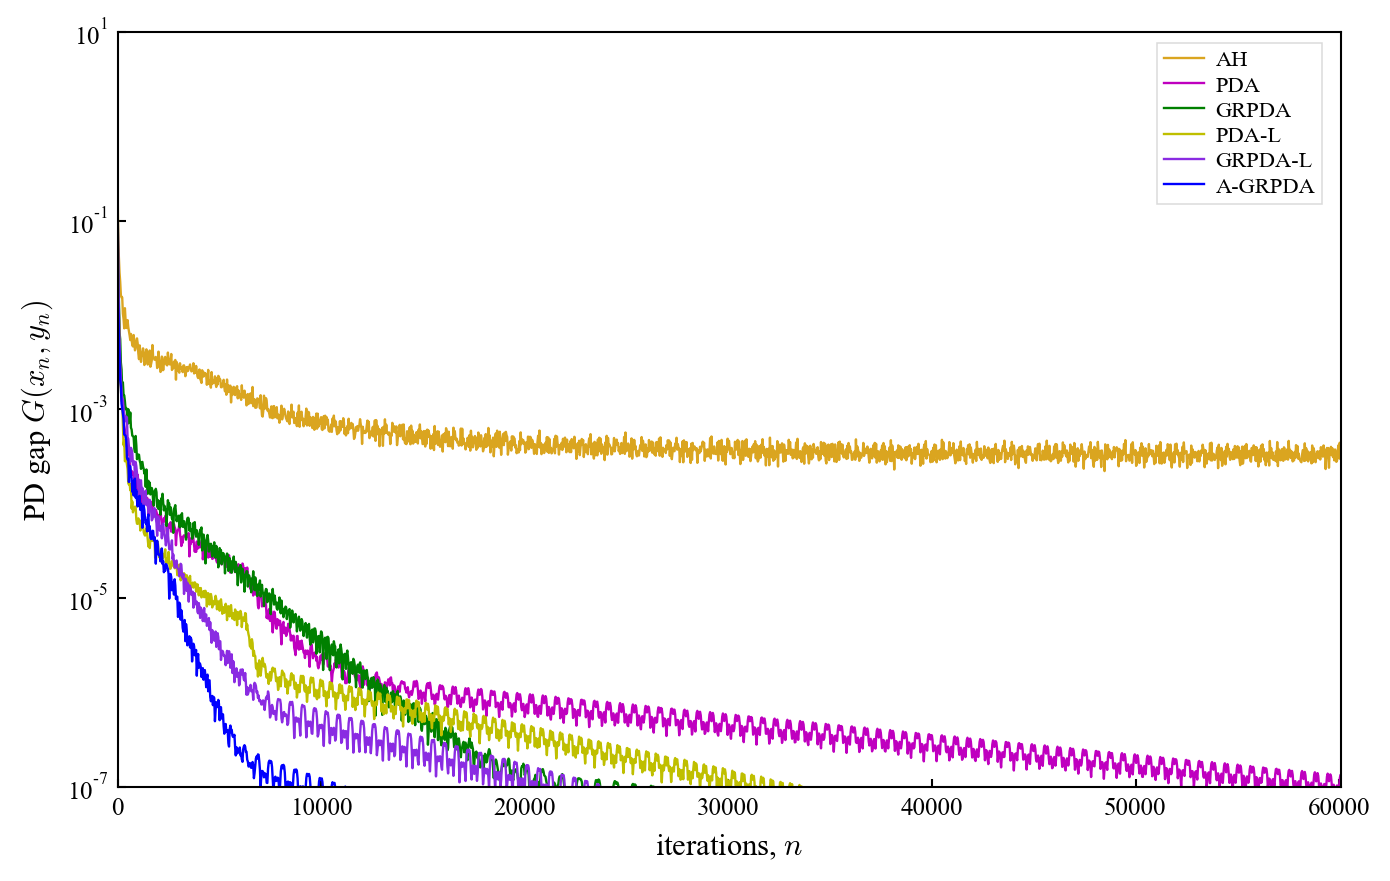

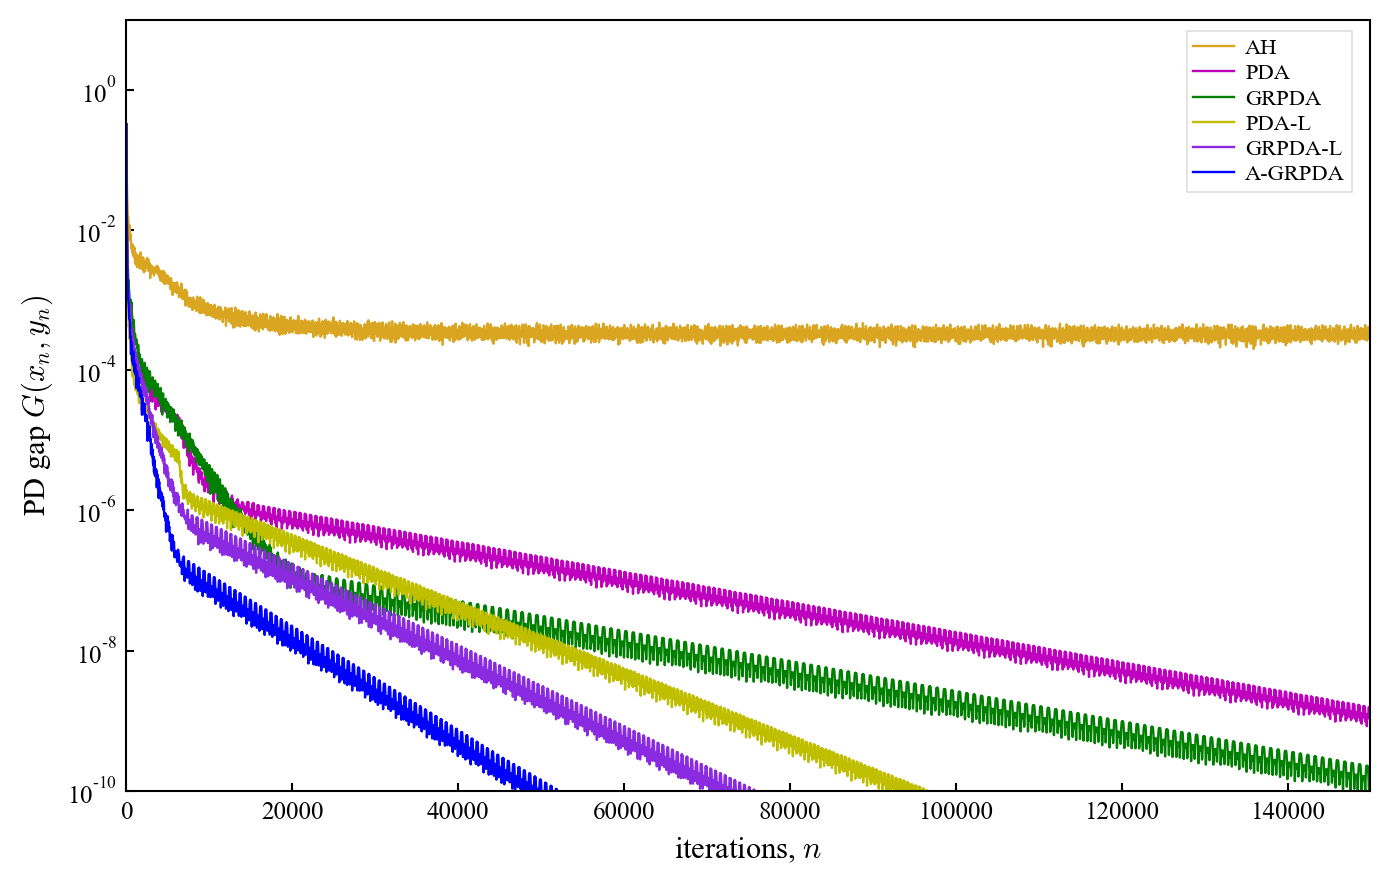

### case_ii_normal_100x100 (100 × 100)

case_ii_normal_100x100 / A-GRPDA: mode=tuned, psi=1.618, beta=0.7, sigma=0.99, tau0=0.078446739, xi_n=1+1.2/n^2, eta_n=0.01/n^2
case_ii_normal_100x100 / AH: N=150000, time=21.83s, gap=0.00795
case_ii_normal_100x100 / PDA: N=150000, time=23.73s, gap=4.15e-08
case_ii_normal_100x100 / GRPDA: N=150000, time=22.52s, gap=4.59e-08
case_ii_normal_100x100 / PDA-L: N=150000, time=29.09s, gap=2.97e-11
case_ii_normal_100x100 / GRPDA-L: N=150000, time=29.46s, gap=9.4e-13
case_ii_normal_100x100 / A-GRPDA: N=150000, time=25.49s, gap=3.8e-13


**首次达到 1e-7 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,达到,123086,19.4351,123086,123086,246172,123086,123086,246172,0,0,0,9.94962e-08
2,GRPDA,达到,119833,18.3565,119833,119833,239666,119833,119833,239666,0,0,0,9.97643e-08
3,PDA-L,达到,60449,12.1353,60450,74369,134819,60449,74368,134817,74368,60449,13919,9.9533e-08
4,GRPDA-L,达到,42999,8.45013,42999,45815,88814,42999,45814,88813,45814,42999,2815,9.93363e-08
5,A-GRPDA,达到,37787,7.33381,37787,37788,75575,37787,37787,75574,0,0,0,9.99066e-08


**首次达到 1e-10 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
3,PDA-L,达到,133527,25.8318,133528,164273,297801,133527,164272,297799,164272,133527,30745,9.98541e-11
4,GRPDA-L,达到,103547,20.3457,103547,110327,213874,103547,110326,213873,110326,103547,6779,9.91066e-11
5,A-GRPDA,达到,98148,17.795,98148,98149,196297,98148,98148,196296,0,0,0,9.91787e-11


**统一迭代预算结束后的六算法完整成本比较**

,Algorithm,Iterations,"Time (s), counted run",A calls (algorithm),A.T calls (algorithm),Operator calls (algorithm),Prox primal,Prox dual,Prox total,LS trials total,LS accepted,LS rejected,Final original J_gap
0,AH,150000,21.829570,150000,150000,300000,150000,150000,300000,0,0,0,7.951351e-03
1,PDA,150000,23.731414,150000,150000,300000,150000,150000,300000,0,0,0,4.148284e-08
2,GRPDA,150000,22.522954,150000,150000,300000,150000,150000,300000,0,0,0,4.587371e-08
3,PDA-L,150000,29.087369,150001,184539,334540,150000,184538,334538,184538,150000,34538,2.969681e-11
4,GRPDA-L,150000,29.457343,150000,159821,309821,150000,159820,309820,159820,150000,9820,9.400883e-13
5,A-GRPDA,150000,25.492903,150000,150001,300001,150000,150000,300000,0,0,0,3.801195e-13


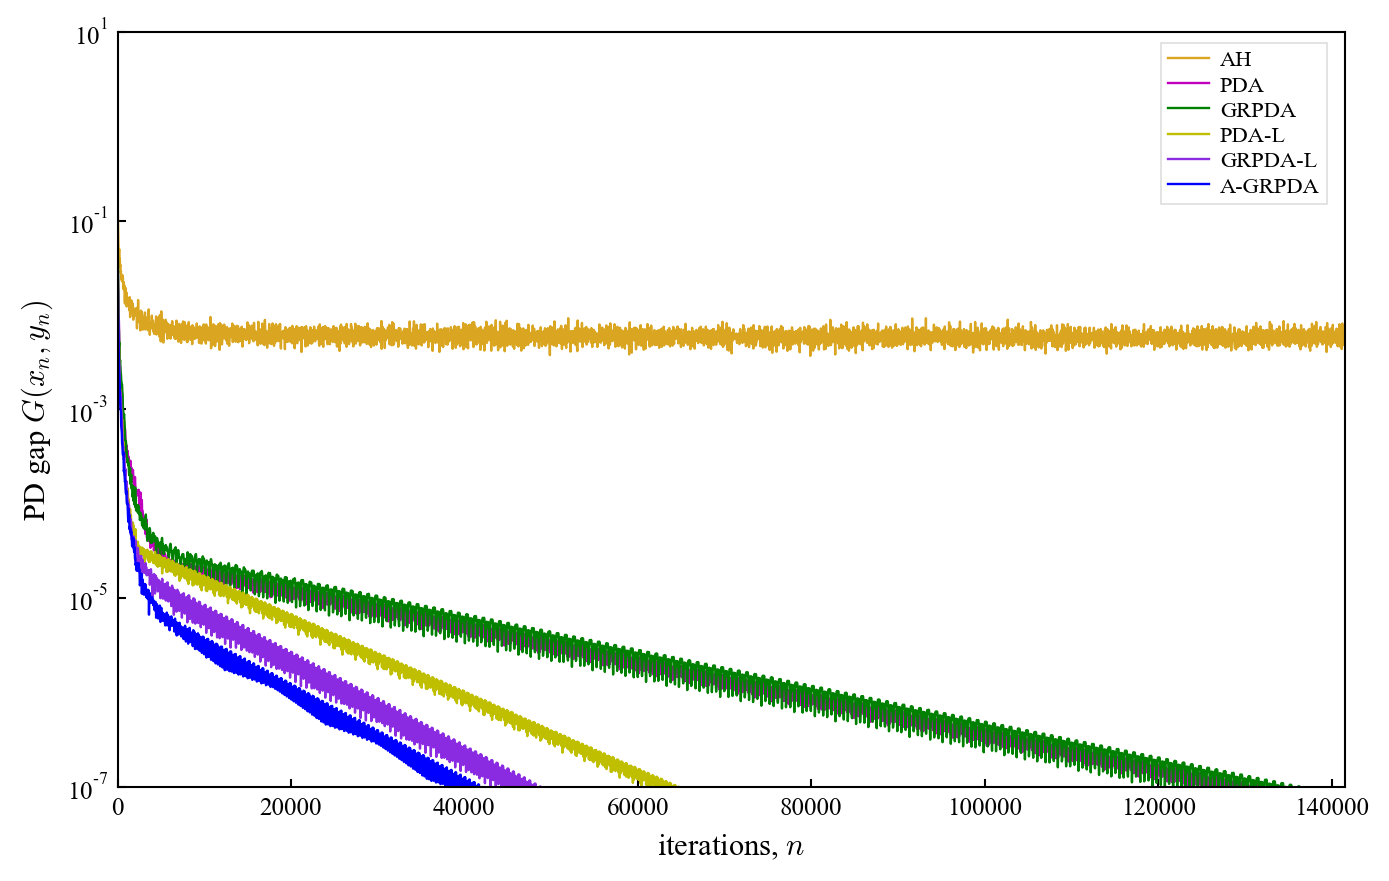

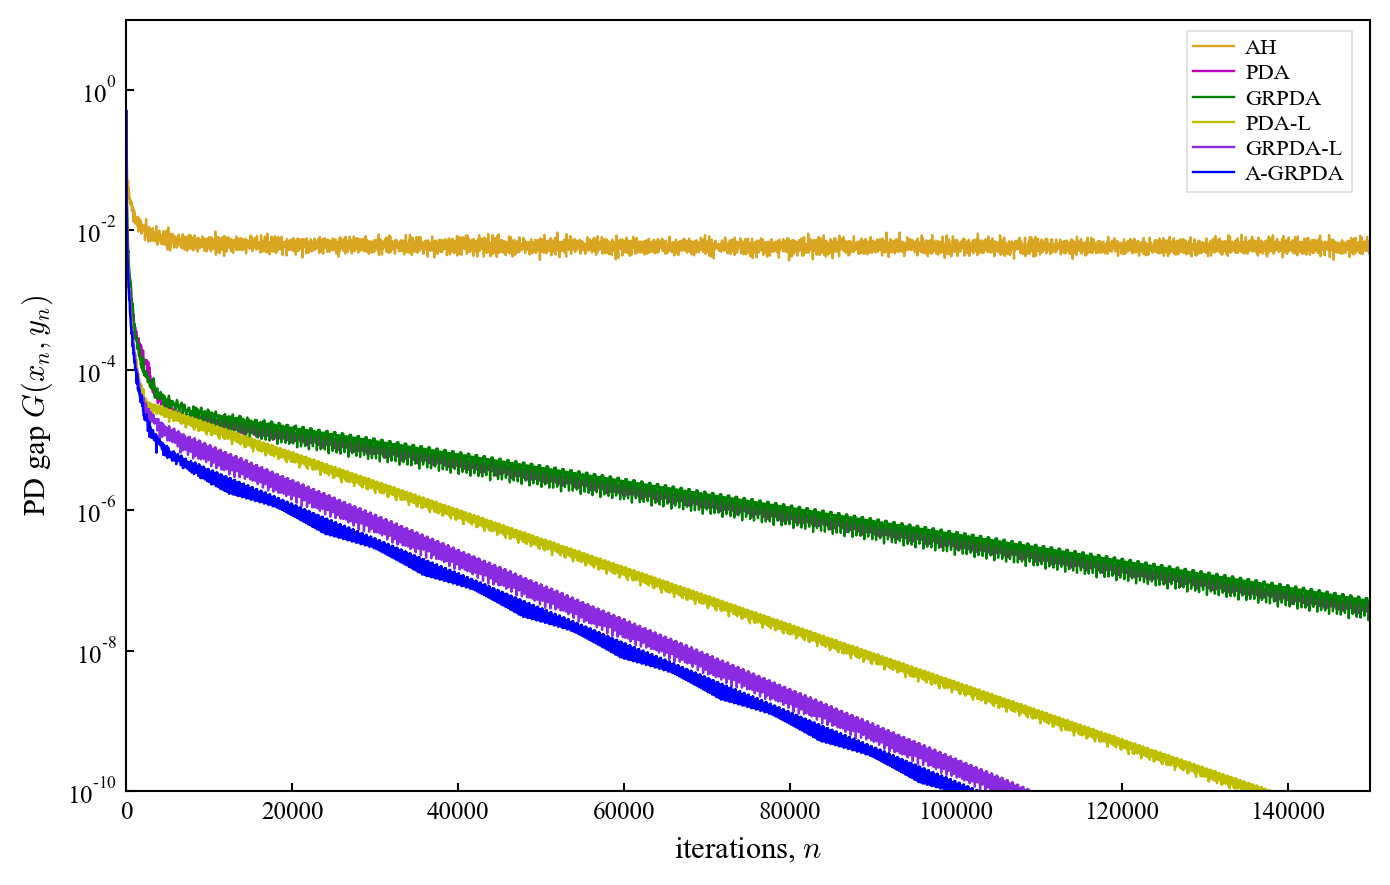

### case_iii_normal_500x500_std10 (500 × 500)

case_iii_normal_500x500_std10 / A-GRPDA: mode=tuned, psi=1.618, beta=0.7, sigma=0.99, tau0=0.0033756599, xi_n=1+1.2/n^2, eta_n=1.0/n^2
case_iii_normal_500x500_std10 / AH: N=150000, time=58.89s, gap=0.00629
case_iii_normal_500x500_std10 / PDA: N=150000, time=57.03s, gap=3.47e-06
case_iii_normal_500x500_std10 / GRPDA: N=150000, time=58.77s, gap=6.17e-06
case_iii_normal_500x500_std10 / PDA-L: N=150000, time=68.44s, gap=2.31e-07
case_iii_normal_500x500_std10 / GRPDA-L: N=150000, time=65.34s, gap=1.57e-07
case_iii_normal_500x500_std10 / A-GRPDA: N=150000, time=66.09s, gap=8.31e-08


**首次达到 1e-7 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
3,PDA-L,未达到,—,—,—,—,—,—,—,—,—,—,—,—
4,GRPDA-L,达到,148250,64.5844,148250,157956,306206,148250,157955,306205,157955,148250,9705,9.99622e-08
5,A-GRPDA,达到,126053,54.5258,126053,126054,252107,126053,126053,252106,0,0,0,9.96891e-08


**首次达到 1e-10 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
3,PDA-L,未达到,—,—,—,—,—,—,—,—,—,—,—,—
4,GRPDA-L,未达到,—,—,—,—,—,—,—,—,—,—,—,—
5,A-GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—


**统一迭代预算结束后的六算法完整成本比较**

,Algorithm,Iterations,"Time (s), counted run",A calls (algorithm),A.T calls (algorithm),Operator calls (algorithm),Prox primal,Prox dual,Prox total,LS trials total,LS accepted,LS rejected,Final original J_gap
0,AH,150000,58.894583,150000,150000,300000,150000,150000,300000,0,0,0,6.286278e-03
1,PDA,150000,57.026404,150000,150000,300000,150000,150000,300000,0,0,0,3.470497e-06
2,GRPDA,150000,58.768830,150000,150000,300000,150000,150000,300000,0,0,0,6.165648e-06
3,PDA-L,150000,68.437304,150001,184539,334540,150000,184538,334538,184538,150000,34538,2.314803e-07
4,GRPDA-L,150000,65.339617,150000,159821,309821,150000,159820,309820,159820,150000,9820,1.569366e-07
5,A-GRPDA,150000,66.086019,150000,150001,300001,150000,150000,300000,0,0,0,8.312759e-08


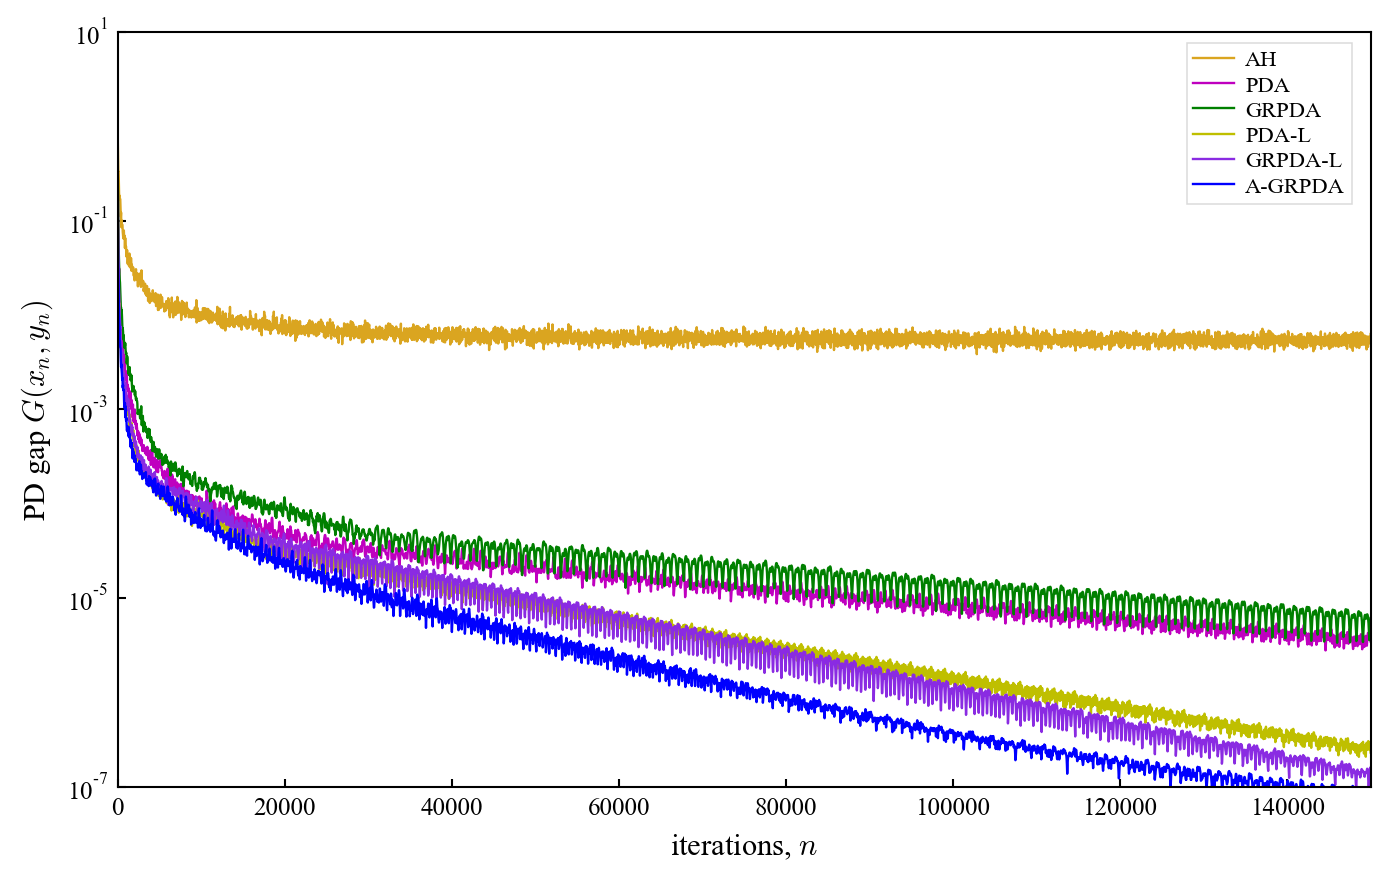

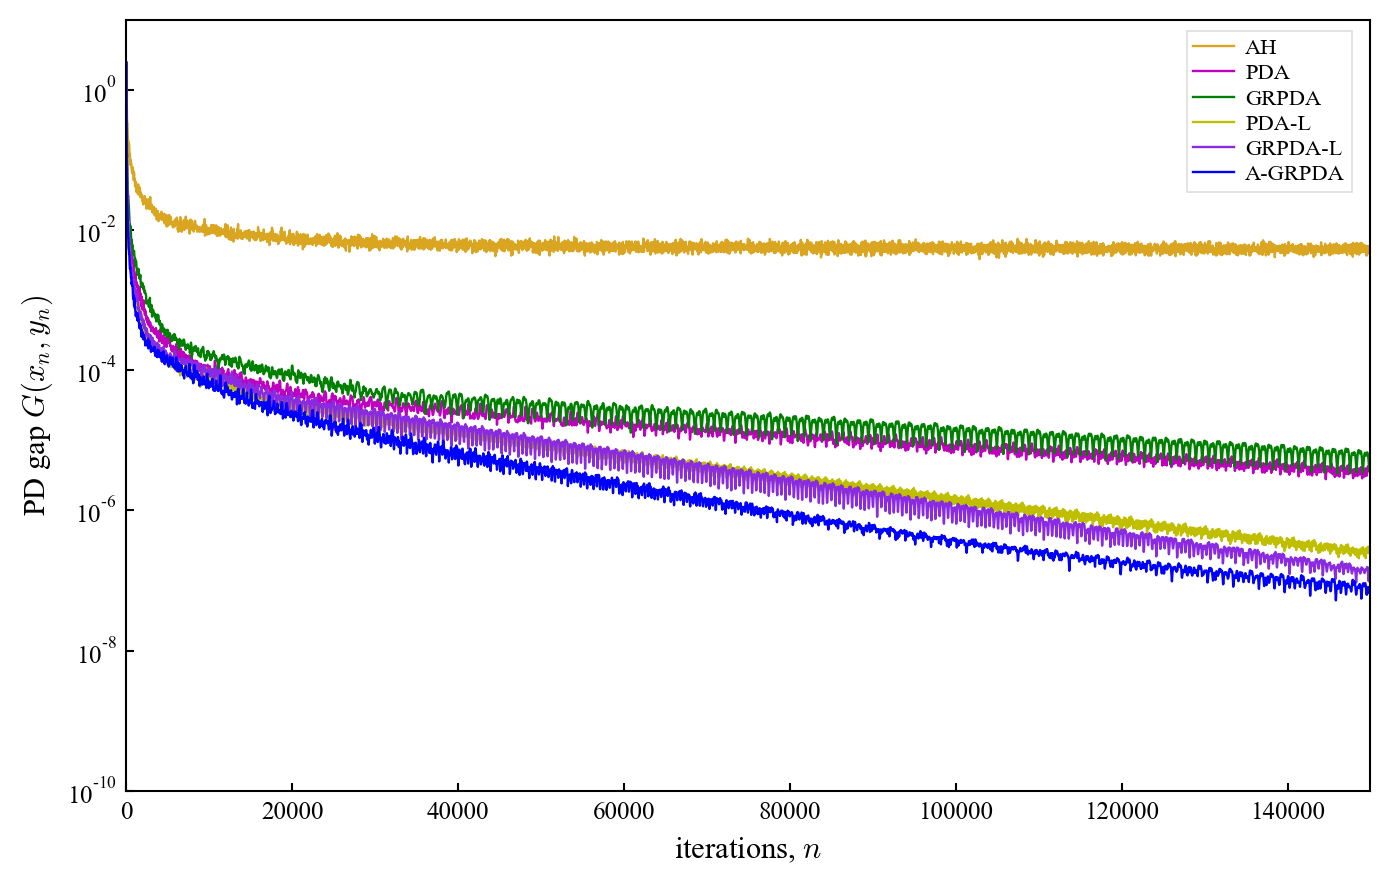

### case_iv_sparse_1000x500 (300 × 600)

case_iv_sparse_1000x500 / A-GRPDA: mode=tuned, psi=1.618, beta=0.7, sigma=0.99, tau0=0.068943015, xi_n=1+1.2/n^2, eta_n=1.0/n^2
case_iv_sparse_1000x500 / AH: N=150000, time=75.55s, gap=3.83e-05
case_iv_sparse_1000x500 / PDA: N=150000, time=74.65s, gap=3.55e-07
case_iv_sparse_1000x500 / GRPDA: N=150000, time=74.30s, gap=7.03e-07
case_iv_sparse_1000x500 / PDA-L: N=150000, time=91.48s, gap=1.05e-07
case_iv_sparse_1000x500 / GRPDA-L: N=150000, time=86.43s, gap=9.21e-08
case_iv_sparse_1000x500 / A-GRPDA: N=150000, time=86.05s, gap=5.04e-09


**首次达到 1e-7 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
3,PDA-L,达到,103802,63.6384,103803,127703,231506,103802,127702,231504,127702,103802,23900,9.99241e-08
4,GRPDA-L,达到,80435,46.7196,80435,85701,166136,80435,85700,166135,85700,80435,5265,9.98792e-08
5,A-GRPDA,达到,40800,24.0363,40800,40801,81601,40800,40800,81600,0,0,0,9.96286e-08


**首次达到 1e-10 时的六算法成本比较**

,Algorithm,Status,Iterations,Time (s),A calls,A.T calls,Operator total,Prox primal,Prox dual,Prox total,LS trials,LS accepted,LS rejected,Gap at hit
0,AH,未达到,—,—,—,—,—,—,—,—,—,—,—,—
1,PDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
2,GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—
3,PDA-L,未达到,—,—,—,—,—,—,—,—,—,—,—,—
4,GRPDA-L,未达到,—,—,—,—,—,—,—,—,—,—,—,—
5,A-GRPDA,未达到,—,—,—,—,—,—,—,—,—,—,—,—


**统一迭代预算结束后的六算法完整成本比较**

,Algorithm,Iterations,"Time (s), counted run",A calls (algorithm),A.T calls (algorithm),Operator calls (algorithm),Prox primal,Prox dual,Prox total,LS trials total,LS accepted,LS rejected,Final original J_gap
0,AH,150000,75.552622,150000,150000,300000,150000,150000,300000,0,0,0,3.828239e-05
1,PDA,150000,74.653060,150000,150000,300000,150000,150000,300000,0,0,0,3.551352e-07
2,GRPDA,150000,74.296063,150000,150000,300000,150000,150000,300000,0,0,0,7.033415e-07
3,PDA-L,150000,91.483717,150001,184538,334539,150000,184537,334537,184537,150000,34537,1.048060e-07
4,GRPDA-L,150000,86.434397,150000,159820,309820,150000,159819,309819,159819,150000,9819,9.211926e-08
5,A-GRPDA,150000,86.047850,150000,150001,300001,150000,150000,300000,0,0,0,5.037669e-09


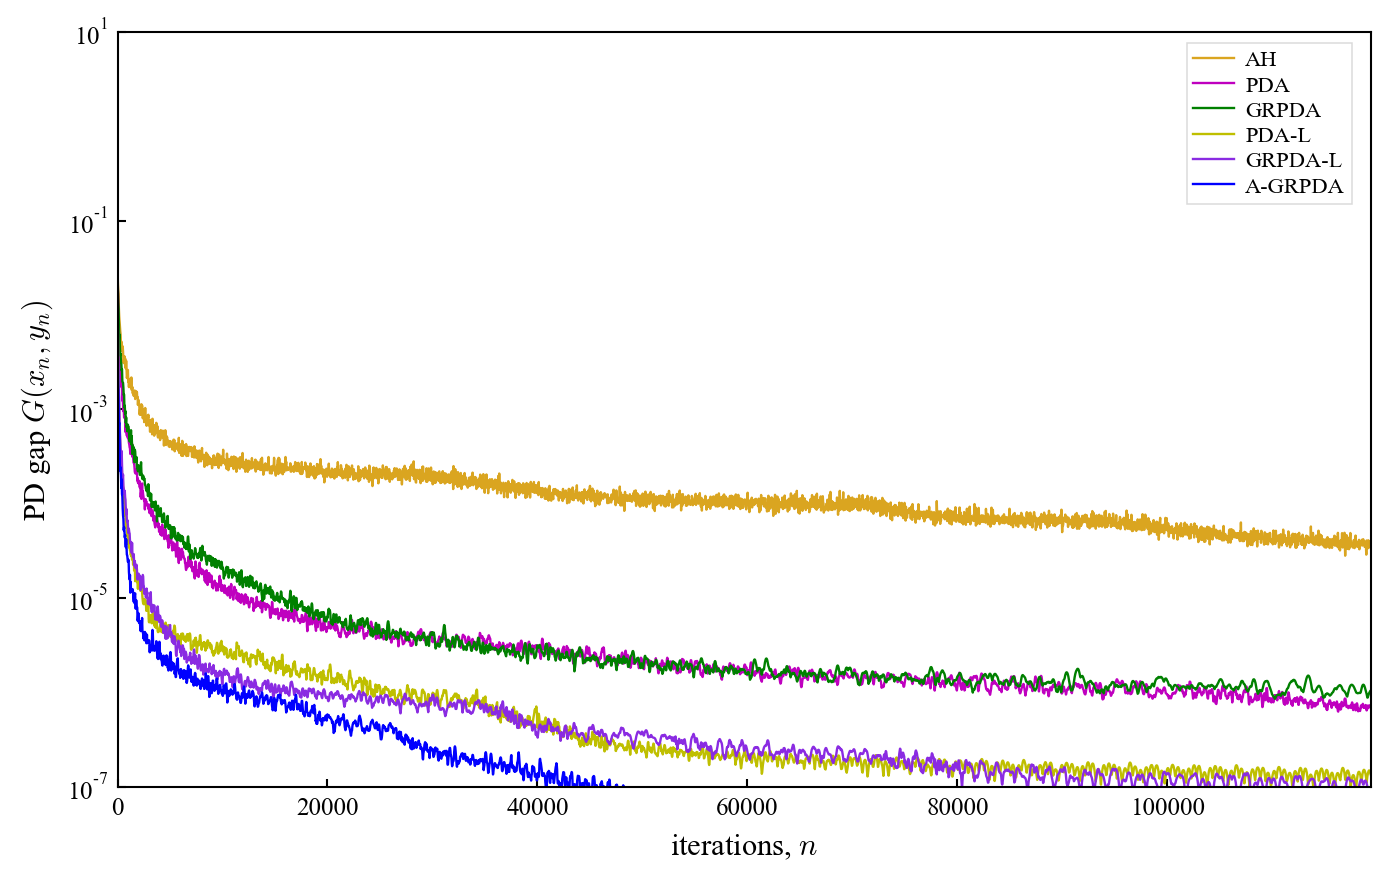

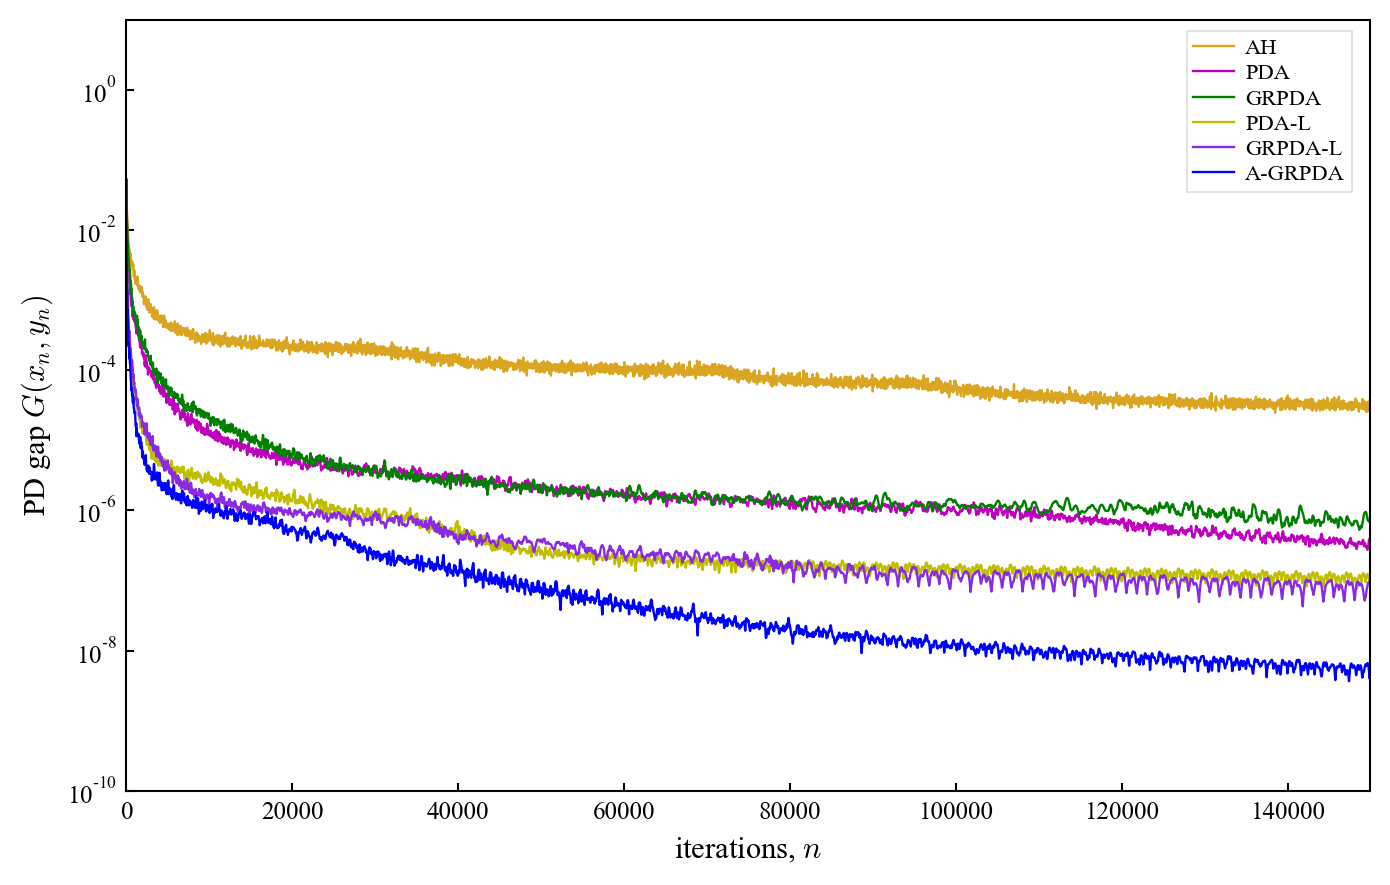


主算法对比表已输出：
 - 每个 Case: comparison_first_hit_1e-7.csv、comparison_first_hit_1e-10.csv
 - 每个 Case: algorithm_comparison_statistics.csv（完整预算）
 - 全部 Case: all_algorithm_comparison_three_views.csv
保存位置: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\matrix_game_results


In [8]:
# 5. 论文四个 Case 的六算法主对比（默认运行）
# 单独运行参数敏感性时，可在设置单元将 RUN_MAIN_COMPARISON 设成 False。
if RUN_MAIN_COMPARISON:
    # 四个 Case 的六算法主对比表（优先输出）
    # 每组先输出两张首次达标成本表（1e-7 / 1e-10），再输出完整预算表。
    # 不修改任何算法、初始参数、J_gap 或敏感性实验。
    from IPython.display import Markdown
    RESULT_DIR.mkdir(parents=True,exist_ok=True)
    main_full_rows=[]
    main_hit_rows={tag: [] for tag,_ in PRECISION_VIEWS}

    # 主实验三个统计口径统一列名，便于直接复制进论文。
    main_hit_columns=['Algorithm','Status','Iterations','Time (s)',
                      'A calls','A.T calls','Operator total',
                      'Prox primal','Prox dual','Prox total',
                      'LS trials','LS accepted','LS rejected','Gap at hit']
    main_full_columns=['Algorithm','Iterations','Time (s), counted run',
                       'A calls (algorithm)','A.T calls (algorithm)','Operator calls (algorithm)',
                       'Prox primal','Prox dual','Prox total',
                       'LS trials total','LS accepted','LS rejected','Final original J_gap']

    for spec in CASE_SPECS:
        case,m,n,kind,density=spec
        display(Markdown(f'### {case} ({m} × {n})'))
        case_dir=RESULT_DIR/case
        case_dir.mkdir(parents=True,exist_ok=True)
        A=make_instance(spec)
        P=initial_parameters(A,spec)
        cfg=agrpda_main_config(P)
        print(f"{case} / A-GRPDA: mode={cfg['mode']}, psi={cfg['psi']}, "
              f"beta={cfg['beta']}, sigma={cfg['sigma']}, tau0={cfg['tau_init']:.8g}, "
              f"xi_n=1+{cfg['xi_coefficient']}/n^2, eta_n={cfg['eta_coefficient']}/n^2")
        case_full=[]
        case_hits={tag: [] for tag,_ in PRECISION_VIEWS}
        curves={}
        for method in METHODS:
            full_row, history, first_hit_rows = run_one_method(method,A,P,MAX_ITER)
            full_row={'Case':case,'m':m,'n':n,'Distribution':kind,**full_row}
            case_full.append(full_row)
            curves[method]=history
            for tag in case_hits:
                case_hits[tag].append({'Case':case,'m':m,'n':n,'Distribution':kind,**first_hit_rows[tag]})
            print(f"{case} / {method}: N={full_row['Iterations']}, "
                  f"time={full_row['Time (s), counted run']:.2f}s, "
                  f"gap={full_row['Final original J_gap']:.3g}",flush=True)
        # 结果分成三张表，避免将完整预算成本误当成首次达标成本。
        for tag,_ in PRECISION_VIEWS:
            display(Markdown(f'**首次达到 {tag} 时的六算法成本比较**'))
            table=pd_tables.DataFrame(case_hits[tag])
            display(table[main_hit_columns].fillna('—'))
            write_rows(case_dir/f'comparison_first_hit_{tag}.csv',case_hits[tag])
            main_hit_rows[tag].extend(case_hits[tag])
        display(Markdown('**统一迭代预算结束后的六算法完整成本比较**'))
        display(pd_tables.DataFrame(case_full)[main_full_columns])
        write_rows(case_dir/'algorithm_comparison_statistics.csv',case_full)
        main_full_rows.extend(case_full)

        save_comparison(case,spec,curves,case_dir,MAX_ITER)
        # Only two iteration-vs-gap figures, in paper order and paper colors.
        # CPU times remain in tables; no CPU-time comparison plot is produced.
        for tag, _ in PRECISION_VIEWS:
            display(Image(filename=str(case_dir/f'comparison_iterations_{tag}.png'), width=700))

    write_rows(RESULT_DIR/'all_cases_statistics.csv',main_full_rows)
    for tag in main_hit_rows:
        write_rows(RESULT_DIR/f'all_cases_comparison_first_hit_{tag}.csv',main_hit_rows[tag])

    # 一张包含全部 Case、全部精度和完整预算记录的主对比总表。
    all_comparison=[]
    for tag,items in main_hit_rows.items():
        for r in items:
            all_comparison.append({**r,'Comparison type':f'first_hit_{tag}'})
    for r in main_full_rows:
        all_comparison.append({
            'Case':r['Case'],'m':r['m'],'n':r['n'],'Distribution':r['Distribution'],
            'Algorithm':r['Algorithm'],'Precision':'full_budget','Status':'运行完预算',
            'Iterations':r['Iterations'],'Time (s)':r['Time (s), counted run'],
            'A calls':r['A calls (algorithm)'],'A.T calls':r['A.T calls (algorithm)'],
            'Operator total':r['Operator calls (algorithm)'],
            'Prox primal':r['Prox primal'],'Prox dual':r['Prox dual'],
            'Prox total':r['Prox total'],'LS trials':r['LS trials total'],
            'LS accepted':r['LS accepted'],'LS rejected':r['LS rejected'],
            'Gap at hit':r['Final original J_gap'],
            'Final gap at budget':r['Final original J_gap'],
            'Maximum iterations':MAX_ITER,'Comparison type':'full_budget',
        })
    write_rows(RESULT_DIR/'all_algorithm_comparison_three_views.csv',all_comparison)
    print('\n主算法对比表已输出：')
    print(' - 每个 Case: comparison_first_hit_1e-7.csv、comparison_first_hit_1e-10.csv')
    print(' - 每个 Case: algorithm_comparison_statistics.csv（完整预算）')
    print(' - 全部 Case: all_algorithm_comparison_three_views.csv')
    print('保存位置:',RESULT_DIR.resolve())

else:
    print('主算法对比已按 RUN_MAIN_COMPARISON=False 跳过；敏感性表格不受影响。')


## 6. A-GRPDA 代表性参数敏感性（精简版）

只在 **Case (i)**（100×100、Uniform[-1,1]、seed=50）运行参数敏感性。四种 Case 的六算法主对比、原始算法公式和参数**均不修改**。

每次只改变一个因素，其他参数保持基准值；四组实验分别形成一张收敛曲线和 CSV 表格。

| 实验组 | 比较内容 | 数量 |
|---|---|---:|
| $\xi_n$ | $1+n^{-1.1}$，$1+n^{-3/2}$，$1+n^{-2}$（基准），$1+n^{-3}$，$1+2/n^2$，$1+2^{-n}$ | 6 |
| $\eta_n$ | $n^{-1.1}$，$n^{-3/2}$，$n^{-2}$（基准），$n^{-3}$，$1/(2n^2)$，$2^{-n}$ | 6 |
| $\psi$ | $1.1,1.3,1.5,1.6$（单独改变） | 4 |
| $\sigma$ | $0.5,0.7,0.9,0.99$（单独改变） | 4 |

基准为 $\xi_n=1+n^{-2}$、$\eta_n=n^{-2}$、$\psi=1.5$、$\sigma=0.99$、$\beta=1$。
改变序列时，保持初始步长 $\tau_0=\tau_1$ 不变；改变 $\psi,\sigma$ 时，按 $\tau_0=\tau_1=\sqrt{\sigma\psi/(\beta\|K\|^2)}$ 联动计算。

总计 **20 条配置、17 种不同参数组合**（基准在四组中重复出现，但只运行一次）。其余实验设置、实际初始步长、调用计数记录到 `sensitivity_parameter_plan.csv`。最大预算为 150,000 次迭代，精度为 PD gap $\le 10^{-6}$。算法在首次达到该精度时立即停止，并记录准确的迭代次数和运行时间；未达到者标记为未达到。


In [9]:
# 参数敏感性：初始化与真实计数（只运行一次）
# 四组参数各自直接输出 1e-6 首次达标表和完整预算表，并保存带局部放大的单张收敛曲线图。
# 此处保留原 A-GRPDA、缓存算子计数、原 J_gap 和参数选择，未更改算法。
if RUN_SENSITIVITY:
    spec = CASE_SPECS[SENS_CASE_INDEX]  # 只使用一个 Case；主算法对比的四个 Case 不变
    A_sens = make_instance(spec)
    P_sens = initial_parameters(A_sens, spec)
    base_J, _ = paper_case_metric(A_sens)
    sens_dir = RESULT_DIR / f'sensitivity_{spec[0]}'
    sens_dir.mkdir(parents=True, exist_ok=True)

    # 敏感性基准：xi_n=1+1/n^2, eta_n=1/n^2。
    # 只更换这一节的两条序列；六算法主对比的默认设置完全不变。
    # 参数定义统一置于第 1 个代码单元；这里不再重复写死每组参数。
    SENS_BASE_KEY = f'pow_{SENS_BASE_EXPONENT:g}'
    SENS_REF = dict(xi_kind=SENS_BASE_KEY, eta_kind=SENS_BASE_KEY,
                    psi=SENS_BASE_PSI, sigma=SENS_BASE_SIGMA)
    def sensitivity_initial_step(psi, sigma):
        return float(np.sqrt(float(psi)*float(sigma)/(P_sens['beta']*P_sens['L']**2)))
    SENS_TAU0 = sensitivity_initial_step(SENS_BASE_PSI, SENS_BASE_SIGMA)
    # 与原 P_sens['tau40'] 数值一致（浮点误差范围内）。
    assert np.isclose(SENS_TAU0,P_sens['tau40'],rtol=1e-12,atol=1e-14)
    SENS_FIG_TAG = '1e-6'

    # 仅保留具有代表性的幂指数、原有系数和几何衰减形式。
    # 两组序列每组 6 条曲线；不再重复绘制指数/系数独立扫描图。
    user_p = tuple(float(v) for v in SENS_POWER_EXPONENTS)
    if (not user_p or len(set(user_p)) != len(user_p) or
            any(not math.isfinite(v) or v <= 1.0 for v in user_p)):
        raise ValueError('SENS_POWER_EXPONENTS 必须是不重复的有限实数，且 p>1')
    exponents = tuple(user_p)
    if 1.1 not in exponents or 1.5 not in exponents or SENS_BASE_EXPONENT not in exponents:
        raise ValueError('代表性指数须至少包含 1.1、1.5、基准 2')
    xi_coeffs = tuple(float(v) for v in SENS_XI_COEFFICIENTS)
    eta_coeffs = tuple(float(v) for v in SENS_ETA_COEFFICIENTS)
    if (not xi_coeffs or not eta_coeffs or
            any(not math.isfinite(c) or c < 0 for c in xi_coeffs+eta_coeffs) or
            1.0 not in xi_coeffs or 1.0 not in eta_coeffs or
            2.0 not in xi_coeffs or 0.5 not in eta_coeffs):
        raise ValueError('xi 系数至少含 (1,2)，eta 系数至少含 (0.5,1)')
    if not SENS_INCLUDE_GEOMETRIC:
        raise ValueError('须保留几何衰减作为代表性选择')

    XI_RULES, ETA_RULES = {}, {}
    for p in exponents:
        key = f'pow_{p:g}'
        XI_RULES[key] = (rf'$1+n^{{-{p:g}}}$',
                         lambda n, p=p: 1.0 + float(n)**(-p))
        ETA_RULES[key] = (rf'$n^{{-{p:g}}}$',
                          lambda n, p=p: float(n)**(-p))
    for c in xi_coeffs:
        if c != 1.0:
            XI_RULES[f'coef_{c:g}'] = (
                rf'$1+{c:g}n^{{-2}}$', lambda n, c=c: 1.0+c*float(n)**(-2))
    for c in eta_coeffs:
        if c != 1.0:
            ETA_RULES[f'coef_{c:g}'] = (
                rf'${c:g}n^{{-2}}$', lambda n, c=c: c*float(n)**(-2))
    XI_RULES['geom'] = (r'$1+2^{-n}$', lambda n: 1.0+2.0**(-n))
    ETA_RULES['geom'] = (r'$2^{-n}$', lambda n: 2.0**(-n))

    xi_keys = [f'pow_{p:g}' for p in exponents] + ['coef_2', 'geom']
    eta_keys = [f'pow_{p:g}' for p in exponents] + ['coef_0.5', 'geom']
    assert len(xi_keys) == len(set(xi_keys)) == 6
    assert len(eta_keys) == len(set(eta_keys)) == 6

    def group_series(keys, kind, rules):
        return [(rules[key][0] + (' (sequence baseline)' if key == SENS_BASE_KEY else ''),
                 {kind: key}) for key in keys]

    sensitivity_groups = {
        'xi_sequences': group_series(xi_keys, 'xi_kind', XI_RULES),
        'eta_sequences': group_series(eta_keys, 'eta_kind', ETA_RULES),
        'psi': [(rf'$\psi={v:g}$' + (' (sequence baseline)' if v == SENS_BASE_PSI else ''),
                 {'psi': v}) for v in SENS_PSI_VALUES],
        'sigma': [(rf'$\sigma={v:g}$' + (' (sequence baseline)' if v == SENS_BASE_SIGMA else ''),
                   {'sigma': v}) for v in SENS_SIGMA_VALUES],
    }

    def validate_sensitivity_parameters(pars):
        psi, sigma = float(pars['psi']), float(pars['sigma'])
        assert math.isfinite(psi) and math.isfinite(sigma)
        assert 1 < psi <= (1 + math.sqrt(5))/2, 'psi 超出黄金比例范围'
        assert 0 < sigma < 1, 'sigma 不在 (0,1)'
        assert pars['xi_kind'] in XI_RULES and pars['eta_kind'] in ETA_RULES
        tau0 = sensitivity_initial_step(psi, sigma)
        assert tau0 > 0 and P_sens['beta'] > 0
        assert tau0 <= np.sqrt(psi*sigma/(P_sens['beta']*P_sens['L']**2))*(1+1e-12)
        # 对本实验预先明确给出的有限族，可和性由 n^-p (p>1) 或 2^-n 保证。
        for k in (1,2,10,100):
            xi = XI_RULES[pars['xi_kind']][1](k)
            eta = ETA_RULES[pars['eta_kind']][1](k)
            assert np.isfinite(xi) and np.isfinite(eta) and xi >= 1 and eta >= 0
        return True

    for _group, _settings in sensitivity_groups.items():
        for _label, _changes in _settings:
            _candidate = SENS_REF.copy()
            _candidate.update(_changes)
            validate_sensitivity_parameters(_candidate)
    print(f'已检查 {sum(map(len, sensitivity_groups.values()))} 条代表性参数配置：'
          'xi_n>=1, eta_n>=0 且两条扰动序列可和；psi、sigma 满足原测试范围。')
    # --------- 参数使用情况：运行前打印并保存，便于论文直接复核 ----------
    sens_param_plan = []
    for group, entries in sensitivity_groups.items():
        for label, changes in entries:
            p = SENS_REF.copy()
            p.update(changes)
            sens_param_plan.append({
                'Group': group, 'Parameter setting': label,
                'xi_n': XI_RULES[p['xi_kind']][0],
                'xi_key': p['xi_kind'], 'eta_key': p['eta_kind'],
                'eta_n': ETA_RULES[p['eta_kind']][0],
                'psi': p['psi'], 'sigma': p['sigma'],
                'beta': P_sens['beta'],
                'tau0': sensitivity_initial_step(p['psi'],p['sigma']),
                'tau1': sensitivity_initial_step(p['psi'],p['sigma']),
                'paper_rule': False,
                'seed': SEED, 'Case': spec[0],
                'shape': f'{A_sens.shape[0]}x{A_sens.shape[1]}',
                'max_iter': SENS_MAX_ITER,
                'tolerance': SENS_PRECISION_VIEWS[0][1],
            })
    param_df = pd_tables.DataFrame(sens_param_plan)
    param_df.to_csv(sens_dir/'sensitivity_parameter_plan.csv',index=False,encoding='utf-8-sig')
    from IPython.display import Markdown
    display(Markdown('### 参数敏感性：四组代表性选择及实际初始步长'))
    display(param_df[['Group','Parameter setting','xi_n','eta_n','psi','sigma','beta','tau0']])
    desc = [
        '# A-GRPDA 参数敏感性实验参数说明',
        f'- Matrix: {spec[0]}, shape={A_sens.shape}, seed={SEED}',
        f'- Maximum iterations: {SENS_MAX_ITER}, precision: {SENS_PRECISION_VIEWS}',
        f'- beta={P_sens["beta"]}, base psi={SENS_BASE_PSI}, base sigma={SENS_BASE_SIGMA}',
        f'- base xi_n={XI_RULES[SENS_BASE_KEY][0]}, eta_n={ETA_RULES[SENS_BASE_KEY][0]}',
        f'- representative exponents: {exponents}',
        f'- representative coefficients: xi {xi_coeffs}, eta {eta_coeffs}',
        '- original four xi choices: 1+1/n^2, 1+1/n^(3/2), 1+2/n^2, 1+2^(-n)',
        '- original four eta choices: 1/n^2, 1/n^(3/2), 1/(2n^2), 2^(-n)',
        f'- initial tau0=tau1=sqrt(sigma*psi/(beta*||A||^2)), base={SENS_TAU0:.12g}',
        '- xi/eta groups: fixed initial tau0/tau1, same matrix and initial point',
        '- psi/sigma groups: initial tau0/tau1 recalculated under the same formula',
        '- paper_rule=False; PD gap max(A x)-min(A.T y)',
        '- Operator and Prox counts exclude diagnostic gap evaluations',
        f'- number of rows: {len(param_df)} (baseline reused across four one-factor groups)',
    ]
    (sens_dir/'sensitivity_parameters.md').write_text('\n'.join(desc)+'\n',encoding='utf-8')
    sens_cache = {}  # 基准组合只运行一次，可复用于不同的单因素组
    sens_hit_rows = {tag: [] for tag, _ in SENS_PRECISION_VIEWS}

    # The algorithm stops at the first attainment of the target tolerance.
    SENS_STOP_TOL = min(float(v) for _, v in SENS_PRECISION_VIEWS)

    def run_sensitivity(xi_kind=SENS_BASE_KEY, eta_kind=SENS_BASE_KEY,
                        psi=SENS_BASE_PSI, sigma=SENS_BASE_SIGMA):
        """Run the original A-GRPDA and stop exactly at the first target hit."""
        validate_sensitivity_parameters(
            dict(xi_kind=xi_kind, eta_kind=eta_kind, psi=psi, sigma=sigma)
        )
        key = (xi_kind, eta_kind, float(psi), float(sigma))
        tau_init = sensitivity_initial_step(psi, sigma)
        if key in sens_cache:
            return sens_cache[key]

        counter = WorkCounter()
        op = CountedOperator(A_sens, counter)
        pg = counted_prox(proj_simplex_prox, counter, 'prox_g')
        pf = counted_prox(proj_simplex_prox, counter, 'prox_f_conj')
        metric_base = counted_metric(base_J, counter, metric_K=1, metric_KT=1)
        thresholds = dict(SENS_PRECISION_VIEWS)
        hits = {}

        # The initial metric evaluation is iteration 0; each later evaluation
        # is made after one completed A-GRPDA iteration.
        def measured_gap(x, y, min_val=0):
            value = metric_base(x, y, min_val)
            iteration = counter.metric_evals - 1
            for tag, threshold in thresholds.items():
                if tag not in hits and value <= threshold:
                    hits[tag] = {
                        'iteration': iteration,
                        'work': counter.as_dict().copy(),
                        'gap': float(value),
                    }
            return value

        initial_gap = float(base_J(P_sens['x0'], P_sens['y0'], 0))
        if initial_gap <= SENS_STOP_TOL:
            raise RuntimeError(
                f'Initial point already satisfies the target ({initial_gap:.6e}); '
                'handle the zero-iteration case separately.'
            )

        with redirect_stdout(io.StringIO()):
            result = pd_Golden1_adaptivestep_tau22(
                measured_gap, pg, pf, op,
                P_sens['x0'].copy(), P_sens['y0'].copy(),
                [tau_init, tau_init], P_sens['beta'], min_val=0,
                numb_iter=SENS_MAX_ITER, tol=SENS_STOP_TOL,
                xi_rule=XI_RULES[xi_kind][1],
                eta_rule=ETA_RULES[eta_kind][1],
                psi=psi, sigma=sigma, paper_rule=False,
            )

        gaps = np.asarray(result[0], dtype=float)
        cpu = np.asarray(result[-2], dtype=float)
        N = len(gaps) - 1
        if N < 0 or N > SENS_MAX_ITER or len(cpu) != N + 1:
            raise AssertionError(
                f'Sensitivity history length: {key}, iterations={N}, '
                f'time entries={len(cpu)}'
            )
        if not np.all(np.isfinite(gaps)):
            raise FloatingPointError(f'Non-finite PD gap in sensitivity run: {key}')

        target_tag = min(SENS_PRECISION_VIEWS, key=lambda item: item[1])[0]
        target_hit = hits.get(target_tag)
        if target_hit is not None:
            if target_hit['iteration'] != N:
                raise AssertionError(
                    f'Algorithm did not stop at its first target hit: '
                    f'{key}, recorded={target_hit["iteration"]}, returned={N}'
                )
            if gaps[-1] > SENS_STOP_TOL:
                raise AssertionError(f'Final gap exceeds tolerance: {key}')
        else:
            if N != SENS_MAX_ITER:
                raise AssertionError(
                    f'Run stopped before the budget without reaching the target: {key}'
                )
            if gaps[-1] <= SENS_STOP_TOL:
                raise AssertionError(
                    f'Final gap meets tolerance but no first-hit snapshot was recorded: {key}'
                )

        # Algorithmic operator/prox counts are checked against the actual
        # number of completed iterations. Gap-evaluation work is separate.
        if counter.K != N or counter.KT != N + 1:
            raise AssertionError(
                f'Operator count mismatch: {key}, K={counter.K}, '
                f'K.T={counter.KT}, iterations={N}'
            )
        if (counter.prox_g, counter.prox_f_conj) != (N, N):
            raise AssertionError(
                f'Prox count mismatch: {key}, {counter.prox_g}, '
                f'{counter.prox_f_conj}, iterations={N}'
            )
        if counter.metric_evals != N + 1:
            raise AssertionError(
                f'Gap evaluation count mismatch: {key}, '
                f'{counter.metric_evals}, iterations={N}'
            )

        for hit in hits.values():
            idx = int(hit['iteration'])
            if idx < 0 or idx >= len(cpu):
                raise AssertionError(f'Invalid first-hit iteration {key}: {idx}')
            hit['time_seconds'] = float(cpu[idx])

        record = {
            'gaps': gaps, 'cpu': cpu, 'work': counter.as_dict(),
            'hits': hits, 'local_updates': int(result[-1]),
            'tau0': tau_init, 'tau1': tau_init,
            'iterations': N, 'reached': target_hit is not None,
            'final_gap': float(gaps[-1]),
        }
        sens_cache[key] = record
        return record

    def sens_cost_row(group, setting, pars, rec, tag=None):
        """Return exact first-hit iteration/time; use dashes if not reached."""
        if tag is None:
            tag = min(SENS_PRECISION_VIEWS, key=lambda item: item[1])[0]
        hit = rec['hits'].get(tag)
        reached = hit is not None
        return {
            'Group': group,
            'Parameter setting': setting,
            'Precision': tag,
            'Status': 'Reached' if reached else f'Not reached within {SENS_MAX_ITER:,}',
            'Iterations': int(hit['iteration']) if reached else '—',
            'Time (s)': float(hit['time_seconds']) if reached else '—',
            'Gap at first hit': float(hit['gap']) if reached else '',
            'Gap at budget': '' if reached else float(rec['final_gap']),
            'Maximum iterations': SENS_MAX_ITER,
        }

    # The displayed table intentionally contains only these three columns.
    sens_show_cols = ['Parameter setting', 'Iterations', 'Time (s)']

    print(
        f'参数敏感性准备完成：{spec[0]}，四组单因素比较，'
        f'目标精度 {SENS_STOP_TOL:.0e}；达到精度立即停止，'
        f'最大预算 {SENS_MAX_ITER:,} 次。'
    )


已检查 20 条代表性参数配置：xi_n>=1, eta_n>=0 且两条扰动序列可和；psi、sigma 满足原测试范围。


### 参数敏感性：四组代表性选择及实际初始步长

,Group,Parameter setting,xi_n,eta_n,psi,sigma,beta,tau0
0,xi_sequences,$1+n^{-1.1}$,$1+n^{-1.1}$,$n^{-2}$,1.5,0.99,1.0,0.112571
1,xi_sequences,$1+n^{-1.5}$,$1+n^{-1.5}$,$n^{-2}$,1.5,0.99,1.0,0.112571
2,xi_sequences,$1+n^{-2}$ (sequence baseline),$1+n^{-2}$,$n^{-2}$,1.5,0.99,1.0,0.112571
3,xi_sequences,$1+n^{-3}$,$1+n^{-3}$,$n^{-2}$,1.5,0.99,1.0,0.112571
4,xi_sequences,$1+2n^{-2}$,$1+2n^{-2}$,$n^{-2}$,1.5,0.99,1.0,0.112571
5,xi_sequences,$1+2^{-n}$,$1+2^{-n}$,$n^{-2}$,1.5,0.99,1.0,0.112571
6,eta_sequences,$n^{-1.1}$,$1+n^{-2}$,$n^{-1.1}$,1.5,0.99,1.0,0.112571
7,eta_sequences,$n^{-1.5}$,$1+n^{-2}$,$n^{-1.5}$,1.5,0.99,1.0,0.112571
8,eta_sequences,$n^{-2}$ (sequence baseline),$1+n^{-2}$,$n^{-2}$,1.5,0.99,1.0,0.112571
9,eta_sequences,$n^{-3}$,$1+n^{-2}$,$n^{-3}$,1.5,0.99,1.0,0.112571


参数敏感性准备完成：case_i_uniform_100x100，四组单因素比较，目标精度 1e-06；达到精度立即停止，最大预算 150,000 次。


In [10]:
# 参数敏感性结果：表格只保留参数设置、首次达标迭代次数和时间
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle

def show_sensitivity_group(group):
    """Run one parameter group and display exact first-hit iterations and times."""
    from IPython.display import Markdown
    if not RUN_SENSITIVITY:
        print('RUN_SENSITIVITY=False，跳过这一组。')
        return

    settings = sensitivity_groups[group]
    group_records = []
    group_hits = {tag: [] for tag, _ in SENS_PRECISION_VIEWS}

    for label, changes in settings:
        pars = SENS_REF.copy()
        pars.update(changes)
        print(f'{group}: 运行/复用 {label}', flush=True)
        rec = run_sensitivity(**pars)
        group_records.append((label, rec))

        for tag, _ in SENS_PRECISION_VIEWS:
            row = sens_cost_row(group, label, pars, rec, tag=tag)
            group_hits[tag].append(row)
            if row['Status'] == 'Reached':
                print(
                    f"  首次达到 {tag}: Iter.={row['Iterations']:,}, "
                    f"Time={row['Time (s)']:.4f} s",
                    flush=True
                )
            else:
                print(
                    f"  未在 {SENS_MAX_ITER:,} 次预算内达到 {tag}; "
                    f"末尾 gap={rec['final_gap']:.6e}",
                    flush=True
                )

    sens_group_results[group] = {'hits': group_hits}
    display(Markdown(f'### {sens_group_titles[group]} · {spec[0]}'))

    for tag, threshold in SENS_PRECISION_VIEWS:
        display(Markdown(
            f'**首次达到 PD gap $\\leq {threshold:.0e}$ 的准确迭代次数与时间**'
        ))
        display(pd_tables.DataFrame(group_hits[tag])[sens_show_cols])
        write_rows(sens_dir / f'{group}_first_hit_{tag}.csv', group_hits[tag])

    # One convergence figure with an inset; the plotted histories stop at
    # the first target hit, or at the maximum budget if the target is missed.
    selected_tag = SENS_FIG_TAG if any(
        tag == SENS_FIG_TAG for tag, _ in SENS_PRECISION_VIEWS
    ) else min(SENS_PRECISION_VIEWS, key=lambda item: item[1])[0]
    cutoff = dict(SENS_PRECISION_VIEWS)[selected_tag]
    hits = [
        int(rec['hits'][selected_tag]['iteration'])
        for _, rec in group_records
        if selected_tag in rec['hits']
    ]

    if len(hits) < len(group_records):
        cap = SENS_MAX_ITER
    else:
        cap = min(SENS_MAX_ITER, max(1000, int(np.ceil(1.12 * max(hits)))))

    if hits:
        h_min, h_max = min(hits), max(hits)
        spread = max(1, h_max - h_min)
        pad = max(180, int(0.12 * spread))
        x0 = max(0, h_min - pad)
        x1 = min(cap, h_max + pad)
        if x1 - x0 < 650:
            mid = (x0 + x1) // 2
            x0 = max(0, mid - 325)
            x1 = min(cap, mid + 325)
    else:
        x0, x1 = int(0.64 * cap), cap

    zoom_bottom = 0.75 * cutoff
    zoom_top = min(12.0 * cutoff, Y_TOP)
    if zoom_top <= zoom_bottom:
        zoom_top = zoom_bottom * 5
    if not hits:
        all_positive = np.concatenate([
            np.asarray(rec['gaps'][:cap+1], dtype=float)
            for _, rec in group_records
        ])
        all_positive = all_positive[
            np.isfinite(all_positive) & (all_positive > 0)
        ]
        if all_positive.size and all_positive.min() > zoom_top:
            zoom_bottom = max(cutoff, float(all_positive.min()) / 1.4)
            zoom_top = max(zoom_bottom * 7.0, float(all_positive.min()) * 2.0)

    curve_colors = list(plt.get_cmap('tab20').colors)
    fig, ax = plt.subplots(figsize=(7.25, 4.45))
    axins = inset_axes(ax, width='41%', height='36%', loc='upper right', borderpad=0.90)

    for j, (label, rec) in enumerate(group_records):
        gaps = np.asarray(rec['gaps'], dtype=float)
        color = curve_colors[j % len(curve_colors)]
        plot_label = label.replace(' (sequence baseline)', '').replace(' (baseline)', '')
        stride = max(1, cap // 3000)
        ix = np.arange(0, min(cap+1, len(gaps)), stride, dtype=int)
        if ix.size == 0 or ix[-1] != min(cap, len(gaps)-1):
            ix = np.r_[ix, min(cap, len(gaps)-1)]
        ax.semilogy(
            ix, np.maximum(gaps[ix], np.finfo(float).tiny),
            label=plot_label, color=color, lw=0.85, linestyle='-'
        )
        zstride = max(1, (x1-x0) // 1400)
        zx = np.arange(x0, min(x1+1, len(gaps)), zstride, dtype=int)
        if zx.size == 0 or zx[-1] != min(x1, len(gaps)-1):
            zx = np.r_[zx, min(x1, len(gaps)-1)]
        axins.semilogy(
            zx, np.maximum(gaps[zx], np.finfo(float).tiny),
            color=color, lw=0.85, linestyle='-'
        )

    ax.set_xlim(0, max(1, cap))
    ax.set_ylim(cutoff, Y_TOP)
    paper_axes(ax)
    if len(settings) >= 8:
        ax.legend(
            loc='upper left', bbox_to_anchor=(0.02, 0.98),
            bbox_transform=ax.transAxes, ncol=2,
            fontsize=6.3 if len(settings) > 12 else 7.0,
            frameon=True, facecolor='white', edgecolor='#d9d9d9',
            columnspacing=0.7, handlelength=1.7, borderpad=0.3
        )
    else:
        paper_legend(
            ax, fontsize=7.0 if len(settings) >= 6 else 7.7,
            loc='upper left', anchor=(0.02, 0.98)
        )

    axins.set_xlim(x0, max(x1, x0+1))
    axins.set_ylim(zoom_bottom, zoom_top)
    axins.set_facecolor('white')
    axins.grid(False)
    axins.set_title('')
    axins.set_xlabel('')
    axins.set_ylabel('')
    axins.tick_params(
        axis='both', which='major', direction='in',
        labelsize=7.0, length=2.5, width=0.65
    )
    axins.tick_params(
        axis='both', which='minor', direction='in',
        length=1.5, width=0.5
    )
    for spine in axins.spines.values():
        spine.set_color('black')
        spine.set_linewidth(0.7)

    box_bottom = max(cutoff, zoom_bottom)
    rect = Rectangle(
        (x0, box_bottom), x1-x0, zoom_top-box_bottom,
        facecolor='none', edgecolor='#777777',
        linestyle=(0, (3, 2)), linewidth=0.65, zorder=4
    )
    ax.add_patch(rect)

    fig.subplots_adjust(left=0.12, right=0.975, bottom=0.145, top=0.98)
    image_file = sens_dir / f'sensitivity_{group}_{selected_tag}_inset.png'
    fig.savefig(image_file, dpi=190, bbox_inches='tight')
    fig.savefig(image_file.with_suffix('.pdf'), bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(image_file), width=820))

    print(f'{group} 的首次达标表和收敛曲线已保存至：{sens_dir}', flush=True)

if RUN_SENSITIVITY:
    sens_group_results = {}
    sens_group_titles = {
        'xi_sequences': '参数敏感性：不同 xi_n 序列（eta_n 固定）',
        'eta_sequences': '参数敏感性：不同 eta_n 序列（xi_n 固定）',
        'psi': '参数敏感性：psi',
        'sigma': '参数敏感性：sigma',
    }


xi_sequences: 运行/复用 $1+n^{-1.1}$
  首次达到 1e-6: Iter.=4,232, Time=0.8485 s
xi_sequences: 运行/复用 $1+n^{-1.5}$
  首次达到 1e-6: Iter.=4,462, Time=0.7903 s
xi_sequences: 运行/复用 $1+n^{-2}$ (sequence baseline)
  首次达到 1e-6: Iter.=5,125, Time=0.9667 s
xi_sequences: 运行/复用 $1+n^{-3}$
  首次达到 1e-6: Iter.=5,135, Time=0.9385 s
xi_sequences: 运行/复用 $1+2n^{-2}$
  首次达到 1e-6: Iter.=4,466, Time=0.8334 s
xi_sequences: 运行/复用 $1+2^{-n}$
  首次达到 1e-6: Iter.=4,491, Time=0.7852 s


### 参数敏感性：不同 xi_n 序列（eta_n 固定） · case_i_uniform_100x100

**首次达到 PD gap $\leq 1e-06$ 的准确迭代次数与时间**

,Parameter setting,Iterations,Time (s)
0,$1+n^{-1.1}$,4232,0.848516
1,$1+n^{-1.5}$,4462,0.790306
2,$1+n^{-2}$ (sequence baseline),5125,0.966698
3,$1+n^{-3}$,5135,0.938523
4,$1+2n^{-2}$,4466,0.833372
5,$1+2^{-n}$,4491,0.785177


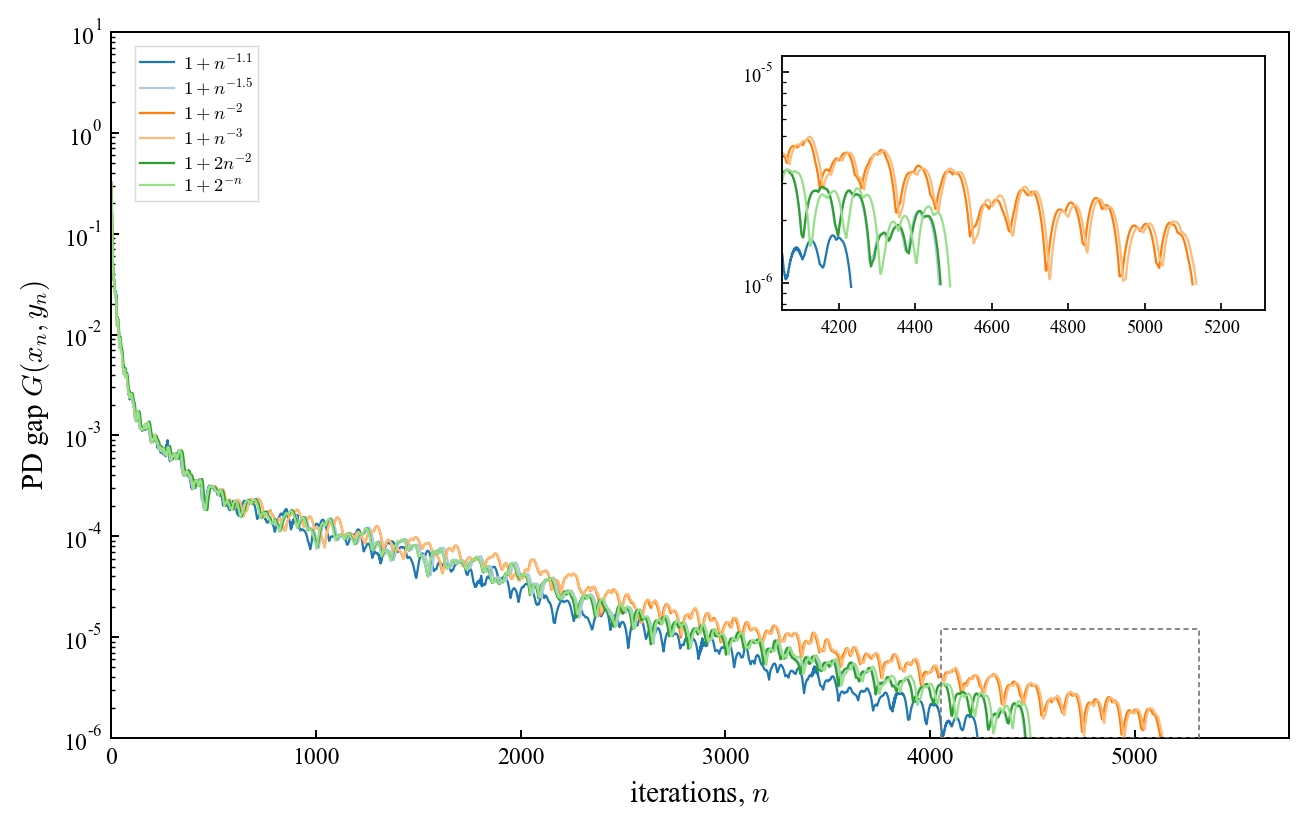

xi_sequences 的首次达标表和收敛曲线已保存至：matrix_game_results\sensitivity_case_i_uniform_100x100


In [11]:
# 比较六种 xi_n 序列，eta_n 固定为 1/n^2。
if RUN_SENSITIVITY:
    show_sensitivity_group('xi_sequences')


eta_sequences: 运行/复用 $n^{-1.1}$
  首次达到 1e-6: Iter.=4,015, Time=0.7148 s
eta_sequences: 运行/复用 $n^{-1.5}$
  首次达到 1e-6: Iter.=4,256, Time=0.7247 s
eta_sequences: 运行/复用 $n^{-2}$ (sequence baseline)
  首次达到 1e-6: Iter.=5,125, Time=0.9667 s
eta_sequences: 运行/复用 $n^{-3}$
  首次达到 1e-6: Iter.=4,354, Time=0.7607 s
eta_sequences: 运行/复用 $0.5n^{-2}$
  首次达到 1e-6: Iter.=4,599, Time=0.8127 s
eta_sequences: 运行/复用 $2^{-n}$
  首次达到 1e-6: Iter.=4,170, Time=0.6913 s


### 参数敏感性：不同 eta_n 序列（xi_n 固定） · case_i_uniform_100x100

**首次达到 PD gap $\leq 1e-06$ 的准确迭代次数与时间**

,Parameter setting,Iterations,Time (s)
0,$n^{-1.1}$,4015,0.714762
1,$n^{-1.5}$,4256,0.724731
2,$n^{-2}$ (sequence baseline),5125,0.966698
3,$n^{-3}$,4354,0.760658
4,$0.5n^{-2}$,4599,0.812706
5,$2^{-n}$,4170,0.691297


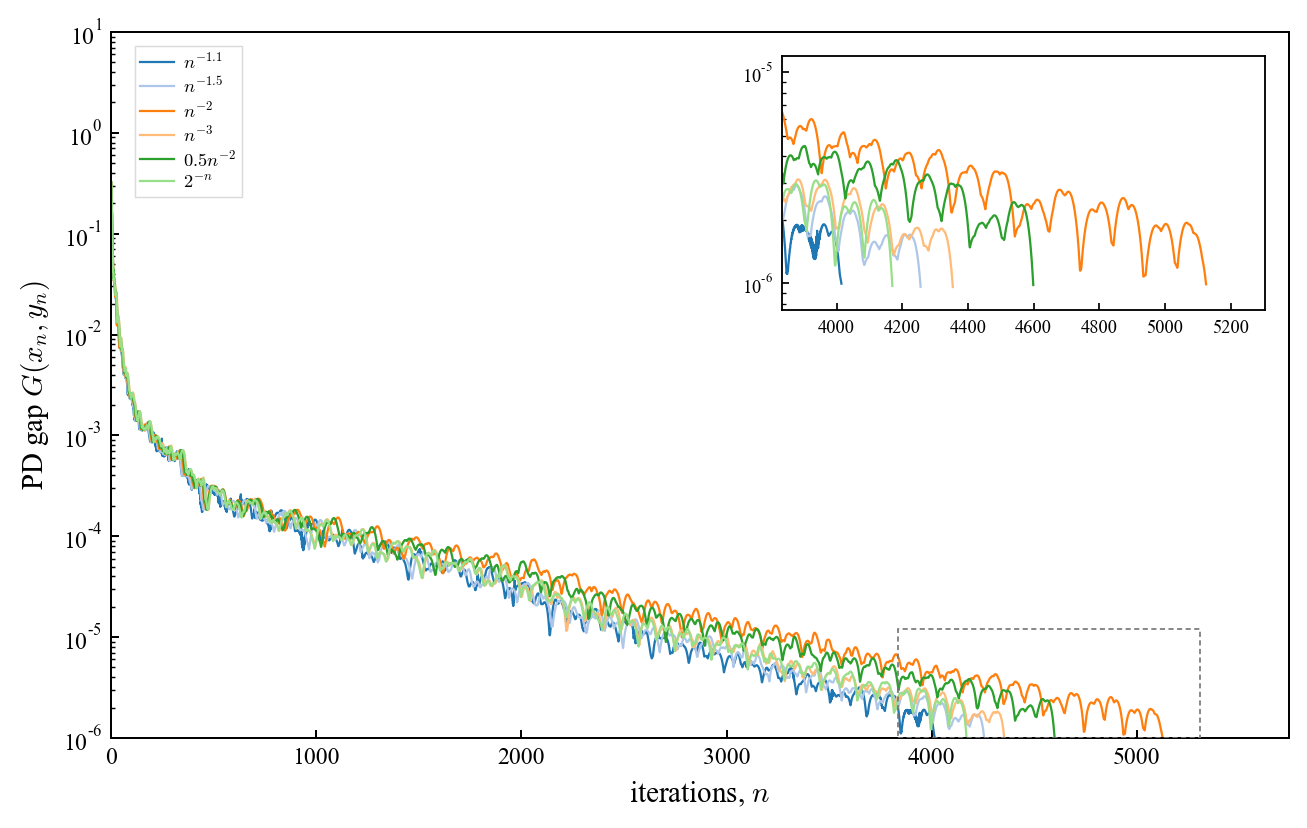

eta_sequences 的首次达标表和收敛曲线已保存至：matrix_game_results\sensitivity_case_i_uniform_100x100


In [12]:
# 比较六种 eta_n 序列，xi_n 固定为 1+1/n^2。
if RUN_SENSITIVITY:
    show_sensitivity_group('eta_sequences')


psi: 运行/复用 $\psi=1.1$
  首次达到 1e-6: Iter.=5,742, Time=1.0594 s
psi: 运行/复用 $\psi=1.3$
  首次达到 1e-6: Iter.=4,262, Time=0.7252 s
psi: 运行/复用 $\psi=1.5$ (sequence baseline)
  首次达到 1e-6: Iter.=5,125, Time=0.9667 s
psi: 运行/复用 $\psi=1.6$
  首次达到 1e-6: Iter.=4,862, Time=1.0230 s


### 参数敏感性：psi · case_i_uniform_100x100

**首次达到 PD gap $\leq 1e-06$ 的准确迭代次数与时间**

,Parameter setting,Iterations,Time (s)
0,$\psi=1.1$,5742,1.059411
1,$\psi=1.3$,4262,0.725157
2,$\psi=1.5$ (sequence baseline),5125,0.966698
3,$\psi=1.6$,4862,1.023032


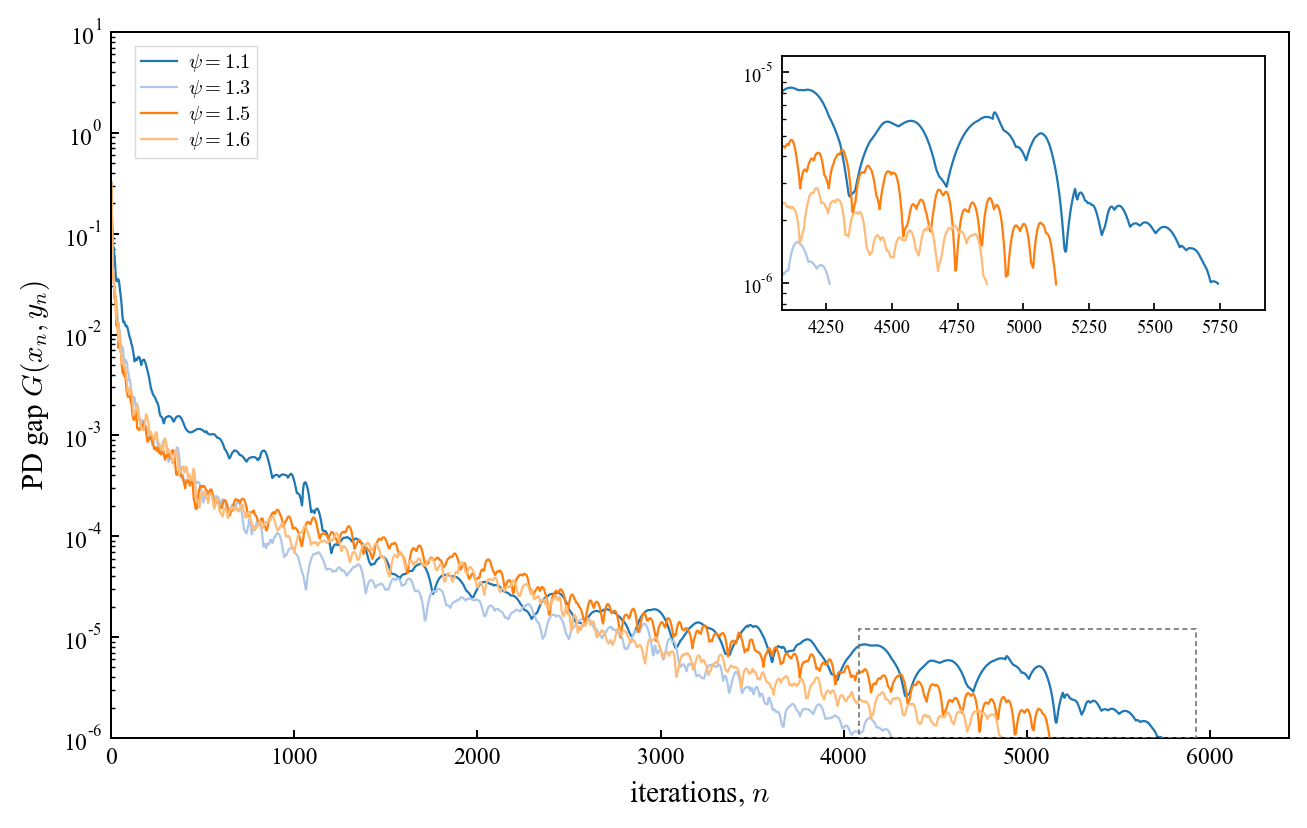

psi 的首次达标表和收敛曲线已保存至：matrix_game_results\sensitivity_case_i_uniform_100x100


In [13]:
# psi 的参数敏感性：直接输出 1e-6 和完整预算的表格，再画迭代图。
# 只运行这一单元也能单独查看该参数组；前面的函数定义单元需先运行。
if RUN_SENSITIVITY:
    show_sensitivity_group('psi')


sigma: 运行/复用 $\sigma=0.5$
  首次达到 1e-6: Iter.=14,745, Time=2.5938 s
sigma: 运行/复用 $\sigma=0.7$
  首次达到 1e-6: Iter.=7,875, Time=1.4065 s
sigma: 运行/复用 $\sigma=0.9$
  首次达到 1e-6: Iter.=5,820, Time=1.0305 s
sigma: 运行/复用 $\sigma=0.99$ (sequence baseline)
  首次达到 1e-6: Iter.=5,125, Time=0.9667 s


### 参数敏感性：sigma · case_i_uniform_100x100

**首次达到 PD gap $\leq 1e-06$ 的准确迭代次数与时间**

,Parameter setting,Iterations,Time (s)
0,$\sigma=0.5$,14745,2.593774
1,$\sigma=0.7$,7875,1.406477
2,$\sigma=0.9$,5820,1.030509
3,$\sigma=0.99$ (sequence baseline),5125,0.966698


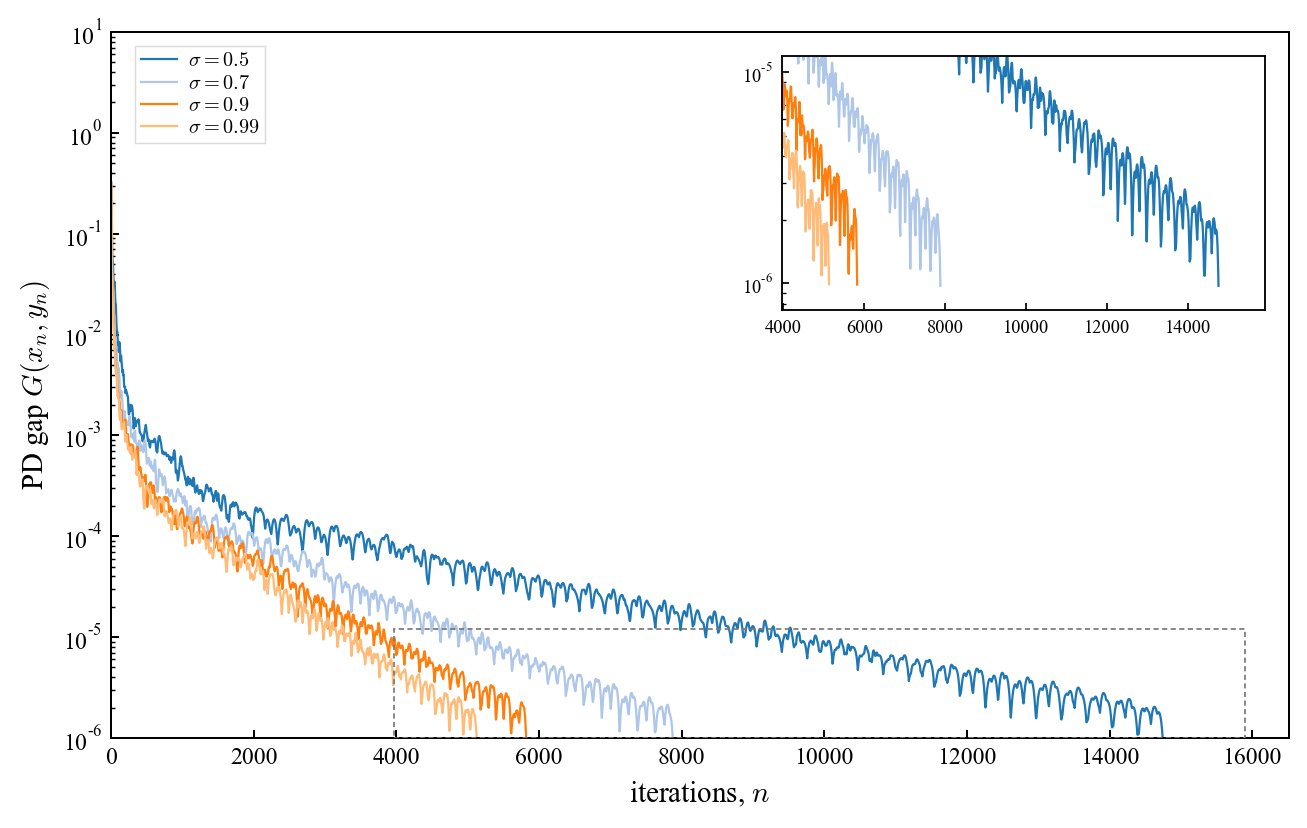

sigma 的首次达标表和收敛曲线已保存至：matrix_game_results\sensitivity_case_i_uniform_100x100


In [14]:
# sigma 的参数敏感性：直接输出 1e-6 和完整预算的表格，再画迭代图。
# 只运行这一单元也能单独查看该参数组；前面的函数定义单元需先运行。
if RUN_SENSITIVITY:
    show_sensitivity_group('sigma')


In [15]:
# 四组参数敏感性总表：只汇总首次达到目标精度时的准确迭代次数与时间
if RUN_SENSITIVITY:
    from IPython.display import Markdown
    missing = [g for g in sensitivity_groups if g not in sens_group_results]
    if missing:
        print('尚未运行的参数组：', ', '.join(missing))
        print('请先执行相应的四组实验单元，再生成完整汇总表。')
    else:
        for tag, _ in SENS_PRECISION_VIEWS:
            rows = [
                row
                for group in sensitivity_groups
                for row in sens_group_results[group]['hits'][tag]
            ]
            display(Markdown(f'### 四组参数敏感性总表：首次达到 {tag}'))
            summary = pd_tables.DataFrame(rows)[
                ['Group', 'Parameter setting', 'Iterations', 'Time (s)']
            ].copy()
            display(summary)
            write_rows(sens_dir / f'sensitivity_first_hit_{tag}_all_groups.csv', rows)
        print('四组参数敏感性首次达标结果已保存至：', sens_dir.resolve())


### 四组参数敏感性总表：首次达到 1e-6

,Group,Parameter setting,Iterations,Time (s)
0,xi_sequences,$1+n^{-1.1}$,4232,0.848516
1,xi_sequences,$1+n^{-1.5}$,4462,0.790306
2,xi_sequences,$1+n^{-2}$ (sequence baseline),5125,0.966698
3,xi_sequences,$1+n^{-3}$,5135,0.938523
4,xi_sequences,$1+2n^{-2}$,4466,0.833372
5,xi_sequences,$1+2^{-n}$,4491,0.785177
6,eta_sequences,$n^{-1.1}$,4015,0.714762
7,eta_sequences,$n^{-1.5}$,4256,0.724731
8,eta_sequences,$n^{-2}$ (sequence baseline),5125,0.966698
9,eta_sequences,$n^{-3}$,4354,0.760658


四组参数敏感性首次达标结果已保存至： D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\matrix_game_results\sensitivity_case_i_uniform_100x100


## 使用说明与文件输出

本 Notebook 同时包含两部分，各自使用**独立的精度和最大迭代次数**：

1. **六算法主对比**：论文四组矩阵，`RUN_MAIN_COMPARISON = True`；最大 **150,000 次**，分别统计 $10^{-7}$、$10^{-10}$ 的首次达标成本并生成两张迭代次数–PD gap 图。
2. **A-GRPDA 参数敏感性**：只使用 Case (i)，`RUN_SENSITIVITY = True`；最大 **150,000 次**，以 $10^{-6}$ 为停止精度；首次达到精度时立即停止，记录准确迭代次数和时间，未达标者如实标记。四组实验分别比较 xi 的六种代表性序列、eta 的六种代表性序列、psi 的四种设置和 sigma 的四种设置；每组生成一张包含局部放大 inset 的 PNG/PDF 收敛曲线；参数敏感性表格仅保留参数设置、首次达标迭代次数和运行时间。

表格直接在 Notebook 内显示并分别保存到 `matrix_game_results/` 的 Case 文件夹及 `sensitivity_<case>/` 文件夹。保留原始 `J_gap`、六算法实现、论文配色和计算成本计数；CPU 时间只在表格中出现。

默认两部分均开启。运行 `Kernel → Restart & Run All` 将先执行四 Case 的主比较，再执行参数敏感性。若只需后者，请将 `RUN_MAIN_COMPARISON = False`。**修改精度后，需重新执行敏感性单元产生新结果；旧精度的缓存输出已移除。** `paper_rule=False` 仍为现有实现选项，尚需与论文公式单独核对。
**参数记录：**运行时自动输出 `sensitivity_parameter_plan.csv`（每组的序列、$\psi$、$\sigma$、$\beta$、实际 $\tau_0=\tau_1$）与 `sensitivity_parameters.md`（固定参数及计数口径），不必再手工对照代码。**$\psi/\sigma$ 改变时初始步长联动更新**，因此这两组曲线可能与之前固定初值的版本不同；六算法主对比不受影响。
